# Homework 3: Frequency Response
## Name: Jon Knapp
### Date: October 20, 2026
### Class: EE 522 Discrete Time Processing

## AI Disclosure:

AI was used in the following ways:
* Code generation
* Markdown formatting
* Derivation assistance


### Helper functions

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# ---------------------------------------------------------------------------
# Signal helpers -- use these when writing h(n)
# ---------------------------------------------------------------------------
def u(n):
    """Unit step u[n] (value 1 at n = 0)."""
    return np.heaviside(np.asarray(n, dtype=float), 1.0)

def delta(n):
    """Unit impulse delta[n]. Written as a comparison so shifts read like the
    math: delta(n - 2) is delta[n-2]. (scipy.signal.unit_impulse works on array
    indices instead of n, which makes shifts awkward.)"""
    return (np.asarray(n) == 0).astype(float)

In [2]:
# ---------------------------------------------------------------------------
# System description
# ---------------------------------------------------------------------------
# Every system is given by h(n), a function of an integer array n.
#
# Optionally also give ba = (b, a) or (b, a, n0): the difference-equation
# coefficients, where b[0] multiplies x[n - n0] (n0 = first nonzero sample of an
# FIR h, e.g. n0 = -3 for system 2; default 0). With ba, SciPy computes
# everything exactly (freqz / lfilter). Without ba, h[n] is truncated to
# -N_TRUNC <= n <= N_TRUNC and summed directly -- needed for systems like
# h[n] = 1 that have no difference-equation form.
N_TRUNC = 200

def _unpack(ba):
    b, a = np.atleast_1d(ba[0]).astype(float), np.atleast_1d(ba[1]).astype(float)
    n0 = ba[2] if len(ba) > 2 else 0
    return b, a, n0

def _h_samples(h, N=N_TRUNC):
    n = np.arange(-N, N + 1)                               # integer n (needed for (-0.8)**n)
    hv = np.asarray(h(n), dtype=float) * np.ones(n.shape)  # allows h = lambda n: 1
    return n, hv

def verify_ba(h, ba, n_max=60):
    """Max difference between h[n] and the impulse response of (b, a, n0)."""
    b, a, n0 = _unpack(ba)
    n = np.arange(n0, n0 + n_max)
    imp = signal.lfilter(b, a, signal.unit_impulse(n_max))
    return np.max(np.abs(imp - np.asarray(h(n), dtype=float) * np.ones(n.shape)))

In [3]:
# ---------------------------------------------------------------------------
# Core computations
# ---------------------------------------------------------------------------
W = np.linspace(-3 * np.pi, 3 * np.pi, 3001)

def _clean(H, rel_tol=1e-10):
    """Zero out round-off-level real/imag parts (e.g. Im ~ 1e-14 for a symmetric h),
    so a real H shows Im = 0 and phase of exactly 0 or pi instead of noise."""
    tol = rel_tol * np.max(np.abs(H))
    re = np.where(np.abs(H.real) < tol, 0.0, H.real)
    im = np.where(np.abs(H.imag) < tol, 0.0, H.imag)
    return re + 1j * im

def freq_response(h, ba=None, w=W):
    """H(e^{jw}). Exact via scipy.signal.freqz if ba is given, else a truncated DTFT."""
    if ba is not None:
        b, a, n0 = _unpack(ba)
        _, H = signal.freqz(b, a, worN=w)
        return _clean(H * np.exp(-1j * w * n0))  # account for a shifted (non-causal) start
    n, hv = _h_samples(h)
    nz = hv != 0
    return _clean(np.exp(-1j * np.outer(w, n[nz])) @ hv[nz])

def system_output(h, x, n_x, ba=None):
    """y = h * x for input samples x on indices n_x (x is zero elsewhere).
    Returns (n_y, y). Uses scipy.signal.lfilter if ba is given, else convolution."""
    x = np.asarray(x, dtype=float)
    if ba is not None:
        b, a, n0 = _unpack(ba)
        pad = len(b) + 300                       # room for FIR tails / IIR decay
        y = signal.lfilter(b, a, np.concatenate([x, np.zeros(pad)]))
        return np.arange(len(y)) + n_x[0] + n0, y
    n_h, hv = _h_samples(h)
    y = signal.convolve(hv, x)
    return np.arange(len(y)) + n_h[0] + n_x[0], y

In [4]:
# ---------------------------------------------------------------------------
# Plot helpers
# ---------------------------------------------------------------------------
def _pi_ticks(ax, wmax=3):
    ks = range(-wmax, wmax + 1)
    names = {0: r"$0$", 1: r"$\pi$", -1: r"$-\pi$"}
    ax.set_xticks([k * np.pi for k in ks])
    ax.set_xticklabels([names.get(k, rf"${k}\pi$") for k in ks])
    ax.set_xlim(-wmax * np.pi, wmax * np.pi)

def _get_ax(ax):
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 3))
    return ax

def _finish(ax, title, xlabel):
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(True, alpha=0.3)
    return ax

In [5]:
# ---------------------------------------------------------------------------
# The seven plots
# ---------------------------------------------------------------------------
def plot_impulse(h, ax=None, n_range=(-15, 15)):
    ax = _get_ax(ax)
    n = np.arange(n_range[0], n_range[1] + 1)
    ax.stem(n, np.asarray(h(n), dtype=float) * np.ones(n.shape), basefmt="k-")
    return _finish(ax, r"Impulse response $h[n]$", r"$n$")

def plot_step_response(h, ax=None, ba=None, n_range=(-15, 50)):
    ax = _get_ax(ax)
    n_x = np.arange(n_range[0] - 50, n_range[1] + 50)
    n_y, y = system_output(h, u(n_x), n_x, ba)
    m = (n_y >= n_range[0]) & (n_y <= n_range[1])
    ax.stem(n_y[m], y[m], basefmt="k-")
    return _finish(ax, r"Step response $y[n] = h[n] * u[n]$", r"$n$")

_rng = np.random.default_rng(0)
X_RAND = _rng.standard_normal(100)   # same N(0,1) input for every system, n = 0..99

def plot_random_response(h, ax=None, ba=None, x=None, n_range=(-15, 115)):
    ax = _get_ax(ax)
    x = X_RAND if x is None else np.asarray(x, dtype=float)
    n_x = np.arange(-50, len(x))                   # zeros before n = 0
    xp = np.concatenate([np.zeros(50), x])
    n_y, y = system_output(h, xp, n_x, ba)
    m = (n_y >= n_range[0]) & (n_y <= n_range[1])
    ax.plot(np.arange(len(x)), x, ".-", color="0.7", lw=0.8, label=r"input $x[n]$")
    ax.plot(n_y[m], y[m], ".-", lw=1.2, label=r"output $y[n]$")
    ax.legend(loc="upper right", fontsize=8)
    return _finish(ax, r"Response to random input $x[n] \sim \mathcal{N}(0,1)$", r"$n$")

def plot_magnitude(h, ax=None, ba=None, w=W):
    ax = _get_ax(ax)
    ax.plot(w, np.abs(freq_response(h, ba, w)))
    _pi_ticks(ax)
    return _finish(ax, r"Magnitude $|H(e^{j\omega})|$", r"$\omega$")

def plot_phase(h, ax=None, ba=None, w=W, tol=1e-6):
    """Wrapped phase angle; points where |H| ~ 0 are hidden (phase undefined there)."""
    ax = _get_ax(ax)
    H = freq_response(h, ba, w)
    ph = np.angle(H)
    ph[np.abs(H) < tol * np.max(np.abs(H))] = np.nan
    ax.plot(w, ph)
    ax.set_yticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
    ax.set_yticklabels([r"$-\pi$", r"$-\pi/2$", r"$0$", r"$\pi/2$", r"$\pi$"])
    _pi_ticks(ax)
    return _finish(ax, r"Phase $\angle H(e^{j\omega})$", r"$\omega$")

def plot_real(h, ax=None, ba=None, w=W):
    ax = _get_ax(ax)
    ax.plot(w, np.real(freq_response(h, ba, w)))
    _pi_ticks(ax)
    return _finish(ax, r"Real part $\mathrm{Re}\{H(e^{j\omega})\}$", r"$\omega$")

def plot_imag(h, ax=None, ba=None, w=W):
    ax = _get_ax(ax)
    ax.plot(w, np.imag(freq_response(h, ba, w)))
    _pi_ticks(ax)
    return _finish(ax, r"Imaginary part $\mathrm{Im}\{H(e^{j\omega})\}$", r"$\omega$")

In [6]:
# ---------------------------------------------------------------------------
# All seven plots for one system
# ---------------------------------------------------------------------------
def analyze(h, title="", ba=None):
    fig, axs = plt.subplots(4, 2, figsize=(13, 13))
    plot_impulse(h, axs[0, 0])
    plot_step_response(h, axs[0, 1], ba)
    plot_random_response(h, axs[1, 0], ba)
    plot_magnitude(h, axs[1, 1], ba)
    plot_phase(h, axs[2, 0], ba)
    plot_real(h, axs[2, 1], ba)
    plot_imag(h, axs[3, 0], ba)
    axs[3, 1].axis("off")
    fig.suptitle(title, fontsize=14)
    fig.tight_layout()
    return fig

### How $y[n]$ and $H(e^{j\omega})$ are computed

For an LTI system with impulse response $h[n]$, the output is the convolution

$$y[n] = (h \ast x)[n] = \sum_{k=-\infty}^{\infty} h[k]\,x[n-k]$$

**Step response** ($x[n] = u[n]$): since $u[n-k] = 1$ only when $k \le n$,

$$s[n] = \sum_{k=-\infty}^{n} h[k], \qquad \lim_{n\to\infty} s[n] = \sum_{k=-\infty}^{\infty} h[k] = H(e^{j0})$$

**Frequency response** (the DTFT of $h[n]$):

$$H(e^{j\omega}) = \sum_{n=-\infty}^{\infty} h[n]\,e^{-j\omega n} = |H(e^{j\omega})|\,e^{j\angle H(e^{j\omega})} = \operatorname{Re}\{H\} + j\,\operatorname{Im}\{H\}$$

$H(e^{j\omega})$ is $2\pi$-periodic, which is why every frequency plot repeats three times over $-3\pi \le \omega \le 3\pi$. For real $h[n]$, $|H|$ and $\operatorname{Re}\{H\}$ are even and $\angle H$ and $\operatorname{Im}\{H\}$ are odd. Plotted phase is wrapped into $(-\pi, \pi]$.

Identities used below:

$$\sum_{n=0}^{M-1} a^n = \frac{1-a^M}{1-a}, \qquad 1 - e^{-j\theta} = 2j\sin(\theta/2)\,e^{-j\theta/2}, \qquad 1 + e^{-j\theta} = 2\cos(\theta/2)\,e^{-j\theta/2}$$

### Problem 1: $h[n] = u[n] - u[n-7]$

#### Derivation

**Step 1: Write out $h[n]$ sample by sample.**

$u[n] = 1$ for $n \ge 0$, and $u[n-7] = 1$ for $n \ge 7$. Subtracting removes everything from $n = 7$ onward, which leaves ones only for $0 \le n \le 6$:

$$h[n] = u[n] - u[n-7] = \begin{cases} 1, & 0 \le n \le 6 \\ 0, & \text{otherwise} \end{cases}$$

| $n$ | $\le -1$ | $0$ | $1$ | $2$ | $3$ | $4$ | $5$ | $6$ | $\ge 7$ |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| $h[n]$ | 0 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 0 |

This is seven ones starting at $n = 0$. Its center of symmetry is $n = 3$. *(Impulse-response plot.)*

---

**Step 2: Output for any input $x[n]$.**

Start from the convolution sum:

$$y[n] = \sum_{k=-\infty}^{\infty} h[k]\,x[n-k]$$

$h[k] = 1$ only for $k = 0, \dots, 6$, so only those seven terms survive:

$$y[n] = \sum_{k=0}^{6} x[n-k] = x[n] + x[n-1] + x[n-2] + x[n-3] + x[n-4] + x[n-5] + x[n-6]$$

Each output is the sum of the current input and the 6 inputs before it, a 7-point moving sum. It uses only present and past inputs. *(Random-input plot: the output is a smoothed, larger version of the input, and it continues until $n = 99 + 6 = 105$.)*

---

**Step 3: Step response, $x[n] = u[n]$.**

Substitute $x[n] = u[n]$ into Step 2:

$$s[n] = \sum_{k=0}^{6} u[n-k]$$

$u[n-k] = 1$ only when $k \le n$, so $s[n]$ counts how many of $k = 0, \dots, 6$ satisfy $k \le n$:

- $n < 0$: no values of $k$ qualify, so $s[n] = 0$
- $0 \le n \le 6$: $k = 0, 1, \dots, n$ qualify, which is $n + 1$ values
- $n > 6$: all 7 values qualify, so $s[n] = 7$

$$s[n] = \begin{cases} 0, & n < 0 \\ n + 1, & 0 \le n \le 6 \\ 7, & n > 6 \end{cases}$$

For example, $s[0] = 1$, $s[3] = 4$, and $s[6] = 7$. *(Step-response plot: a ramp from $n = 0$ that levels off at 7.)*

---

**Step 4: Frequency response, written out term by term.**

Start from the DTFT definition. Only the seven nonzero samples contribute:

$$H(e^{j\omega}) = \sum_{n=-\infty}^{\infty} h[n]\,e^{-j\omega n} = \sum_{n=0}^{6} e^{-j\omega n} = 1 + e^{-j\omega} + e^{-j2\omega} + e^{-j3\omega} + e^{-j4\omega} + e^{-j5\omega} + e^{-j6\omega}$$

Use $e^{-j\theta} = \cos\theta - j\sin\theta$ on every term to split real and imaginary parts:

$$\operatorname{Re}\{H\} = 1 + \cos\omega + \cos 2\omega + \cdots + \cos 6\omega, \qquad
\operatorname{Im}\{H\} = -\left(\sin\omega + \sin 2\omega + \cdots + \sin 6\omega\right)$$

Unlike Problem 2, the sine terms don't cancel, because $h[n]$ is not symmetric about $n = 0$. So $H$ is complex.

---

**Step 5: Closed form (explains the shape of the plots).**

Use the finite geometric series $\sum_{m=0}^{M-1} a^m = \dfrac{1-a^M}{1-a}$ with $a = e^{-j\omega}$ and $M = 7$:

$$H(e^{j\omega}) = \sum_{n=0}^{6} \left(e^{-j\omega}\right)^n = \frac{1 - e^{-j7\omega}}{1 - e^{-j\omega}}$$

Factor half of each exponent out of the numerator and denominator, then use $e^{j\theta} - e^{-j\theta} = 2j\sin\theta$:

$$\begin{aligned}
1 - e^{-j7\omega} &= e^{-j7\omega/2}\left(e^{j7\omega/2} - e^{-j7\omega/2}\right) = e^{-j7\omega/2}\cdot 2j\sin(7\omega/2) \\
1 - e^{-j\omega} &= e^{-j\omega/2}\left(e^{j\omega/2} - e^{-j\omega/2}\right) = e^{-j\omega/2}\cdot 2j\sin(\omega/2)
\end{aligned}$$

Divide. The $2j$ cancels, and $e^{-j7\omega/2} / e^{-j\omega/2} = e^{-j3\omega}$:

$$\boxed{H(e^{j\omega}) = e^{-j3\omega}\,\frac{\sin(7\omega/2)}{\sin(\omega/2)}}$$

The answer has two parts: a real amplitude, $\dfrac{\sin(7\omega/2)}{\sin(\omega/2)}$, which is exactly Problem 2's $H$, multiplied by a pure phase factor $e^{-j3\omega}$ that comes from the 3-sample delay to the center of $h[n]$.

---

**Step 6: Magnitude, phase, real, and imaginary parts.**

Let $A(\omega) = \dfrac{\sin(7\omega/2)}{\sin(\omega/2)}$ (real). Since $\lvert e^{-j3\omega}\rvert = 1$:

$$|H(e^{j\omega})| = |A(\omega)| = \left|\frac{\sin(7\omega/2)}{\sin(\omega/2)}\right|$$

$$\angle H(e^{j\omega}) = \begin{cases} -3\omega, & A(\omega) > 0 \\ -3\omega + \pi, & A(\omega) < 0 \end{cases} \quad \text{(then wrapped into } (-\pi, \pi]\text{)}$$

Expand $e^{-j3\omega} = \cos 3\omega - j\sin 3\omega$:

$$\operatorname{Re}\{H\} = \cos(3\omega)\,A(\omega), \qquad \operatorname{Im}\{H\} = -\sin(3\omega)\,A(\omega)$$

The phase is a straight line with slope $-3$, but wrapping it into $(-\pi, \pi]$ turns it into the steep sawtooth in the plot, with extra jumps of $\pi$ wherever $A(\omega)$ changes sign.

---

**Step 7: Key values to check against the plots.**

| Quantity | Value | Where to see it |
|:---|:---|:---|
| $H(e^{j0})$ | $1 + 1 + \cdots + 1 = 7$ | Peak of magnitude and real part; final value of the step response |
| $H(e^{j\pi})$ | $1 - 1 + 1 - 1 + 1 - 1 + 1 = 1$ | Magnitude equals 1 at $\omega = \pm\pi$ |
| Zeros of $H$ | $\sin(7\omega/2) = 0 \Rightarrow \omega = \pm\tfrac{2\pi}{7}, \pm\tfrac{4\pi}{7}, \pm\tfrac{6\pi}{7}$ | Magnitude touches 0 six times per period, the same as Problem 2 |
| Phase slope | $-3$ (a 3-sample delay) | Sawtooth in the phase plot |
| $\operatorname{Im}\{H\}$ | Odd; 0 at $\omega = 0$; extremes $\approx \pm 4.7$ | Imaginary-part plot |
| Period | $2\pi$ | Every frequency plot repeats at $\omega = \pm 2\pi$ |

ba check: 0.0


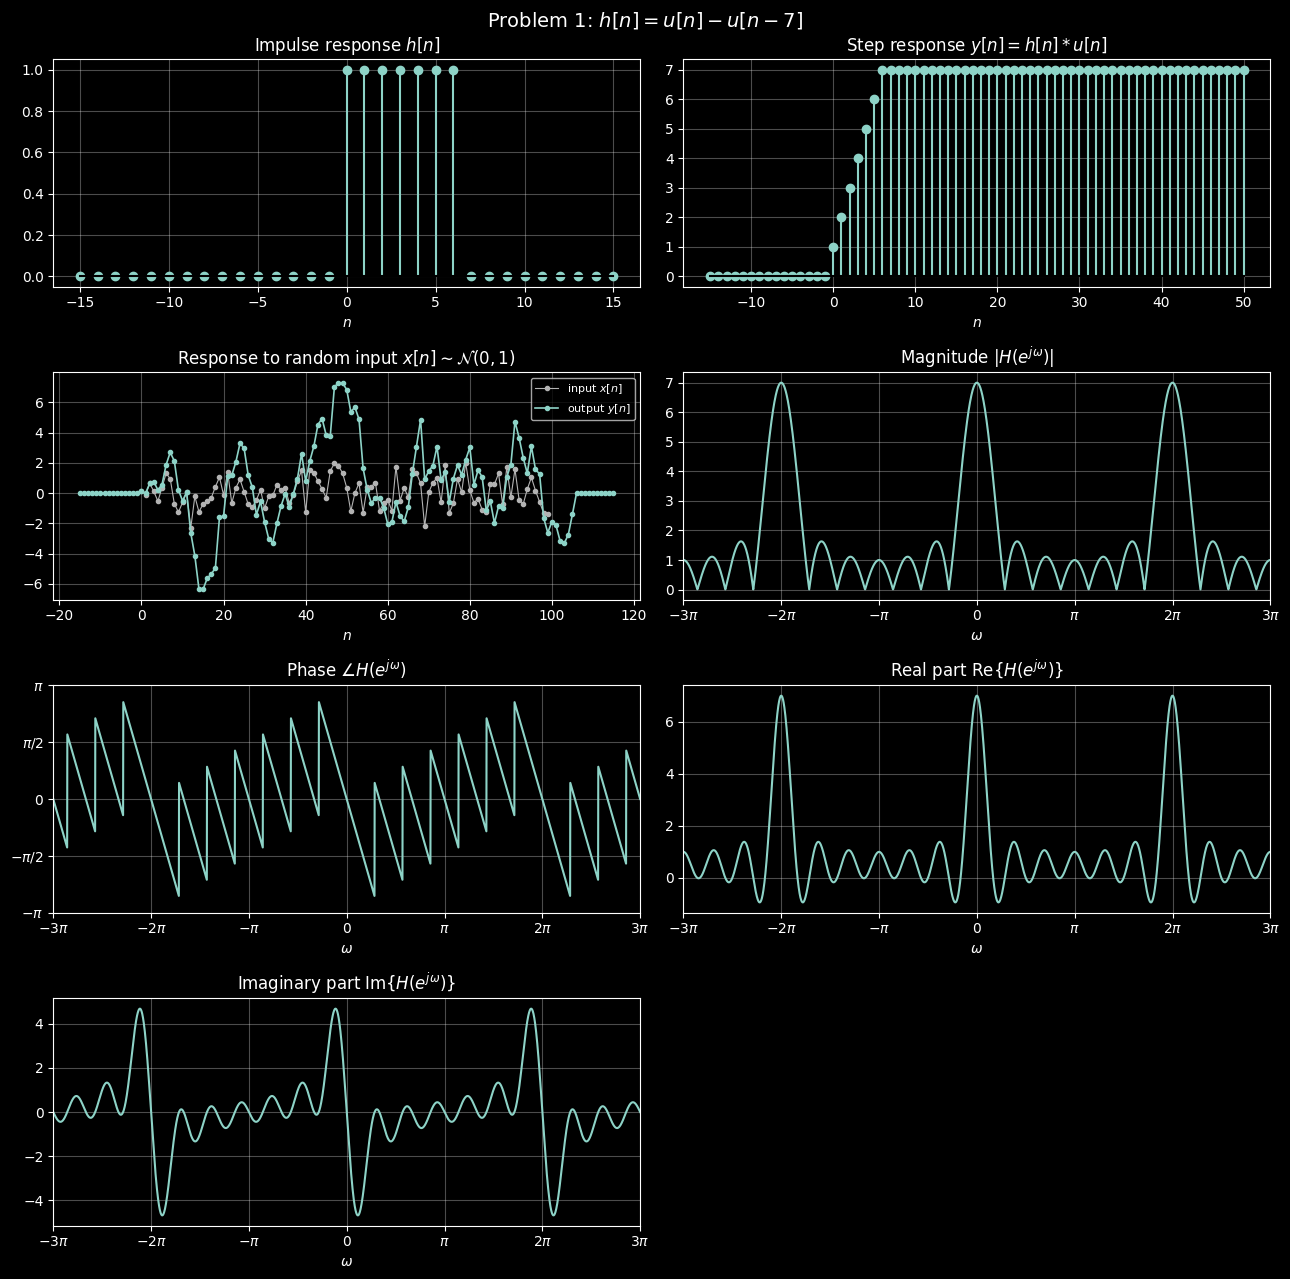

In [7]:
h1 = lambda n: u(n) - u(n - 7)
ba1 = (np.ones(7), [1])                      # FIR: 7 ones starting at n = 0

print("ba check:", verify_ba(h1, ba1))
analyze(h1, r"Problem 1: $h[n] = u[n] - u[n-7]$", ba1)
plt.show()

#### Classification

| Property        | Answer             | Justification                                                                                                      |
|:----------------|:-------------------|:-------------------------------------------------------------------------------------------------------------------|
| **Filter type** | Lowpass            | When I compare $\lvert H(e^{j\omega})\rvert$ at ω = 0 (DC) and ω = π, the peak is at ω = 0 and is small at ω = π   |
| **Causality**   | Causal             | $h[n] = 0$ for all n < 0                                                                                           |
| **Stability**   | Stable   | $\Sigma{\lvert h[n] \rvert} < \infty$                                                                              |
| **FIR or IIR**  | FIR          | There are only 7 nonzero samples                                                                                   |

<!--
Filter type: compare |H(e^{jω})| at ω = 0 (DC) and ω = π, and look for peaks or notches in between.
  Lowpass: largest near 0, small near π.   Highpass: small near 0, largest near π.
  Bandpass: small at both 0 and π, peak in between.   Bandstop: large at 0 and π, notch in between.
Causality: causal if and only if h[n] = 0 for all n < 0 (check the impulse-response plot left of n = 0).
Stability (BIBO): stable if and only if Σ|h[n]| < ∞. For a rational H(z), equivalently all poles have |p| < 1.
  Also visible in the step response: it should settle to a finite value H(e^{j0}).
FIR vs IIR: FIR if h[n] has a finite number of nonzero samples, IIR otherwise.
-->

### Problem 2: $h[n] = u[n+3] - u[n-4]$

#### Derivation

**Step 1: Write out $h[n]$ sample by sample.**

$u[n+3] = 1$ for $n \ge -3$, and $u[n-4] = 1$ for $n \ge 4$. Subtracting removes everything from $n = 4$ onward, which leaves ones only for $-3 \le n \le 3$:

$$h[n] = u[n+3] - u[n-4] = \begin{cases} 1, & -3 \le n \le 3 \\ 0, & \text{otherwise} \end{cases}$$

| $n$ | $\le -4$ | $-3$ | $-2$ | $-1$ | $0$ | $1$ | $2$ | $3$ | $\ge 4$ |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| $h[n]$ | 0 | 1 | 1 | 1 | 1 | 1 | 1 | 1 | 0 |

This is seven ones centered on $n = 0$, the same as Problem 1 shifted 3 samples to the left. *(Impulse-response plot.)*

---

**Step 2: Output for any input $x[n]$.**

Start from the convolution sum:

$$y[n] = \sum_{k=-\infty}^{\infty} h[k]\,x[n-k]$$

$h[k] = 1$ only for $k = -3, \dots, 3$, so only those seven terms survive:

$$y[n] = \sum_{k=-3}^{3} x[n-k] = x[n+3] + x[n+2] + x[n+1] + x[n] + x[n-1] + x[n-2] + x[n-3]$$

Each output is the sum of the current input, the 3 inputs before it, and the 3 inputs after it. Because it needs future inputs ($x[n+1]$, $x[n+2]$, $x[n+3]$), the system is non-causal. *(Random-input plot: the output starts at $n = -3$, before the input starts at $n = 0$, and is a smoothed version of the input.)*

---

**Step 3: Step response, $x[n] = u[n]$.**

Substitute $x[n] = u[n]$ into Step 2:

$$s[n] = \sum_{k=-3}^{3} u[n-k]$$

$u[n-k] = 1$ only when $k \le n$, so $s[n]$ counts how many of $k = -3, \dots, 3$ satisfy $k \le n$:

- $n < -3$: no values of $k$ qualify, so $s[n] = 0$
- $-3 \le n \le 3$: $k = -3, -2, \dots, n$ qualify, which is $n - (-3) + 1 = n + 4$ values
- $n > 3$: all 7 values qualify, so $s[n] = 7$

$$s[n] = \begin{cases} 0, & n < -3 \\ n + 4, & -3 \le n \le 3 \\ 7, & n > 3 \end{cases}$$

For example, $s[-3] = 1$, $s[0] = 4$, and $s[3] = 7$. *(Step-response plot: a ramp from $n = -3$ that levels off at 7.)*

---

**Step 4: Frequency response, written out term by term.**

Start from the DTFT definition. Only the seven nonzero samples contribute:

$$H(e^{j\omega}) = \sum_{n=-\infty}^{\infty} h[n]\,e^{-j\omega n} = \sum_{n=-3}^{3} e^{-j\omega n}$$

Write out all seven terms:

$$H(e^{j\omega}) = e^{j3\omega} + e^{j2\omega} + e^{j\omega} + 1 + e^{-j\omega} + e^{-j2\omega} + e^{-j3\omega}$$

Group each positive exponent with its negative partner:

$$H(e^{j\omega}) = 1 + \left(e^{j\omega} + e^{-j\omega}\right) + \left(e^{j2\omega} + e^{-j2\omega}\right) + \left(e^{j3\omega} + e^{-j3\omega}\right)$$

Apply Euler's formula, $e^{j\theta} + e^{-j\theta} = 2\cos\theta$, to each pair:

$$\boxed{H(e^{j\omega}) = 1 + 2\cos\omega + 2\cos 2\omega + 2\cos 3\omega}$$

Every term is a real cosine, so $H(e^{j\omega})$ is **purely real**. This happens because $h[n]$ is symmetric about $n = 0$ ($h[n] = h[-n]$).

---

**Step 5: Closed form (explains the shape of the plots).**

Re-index with $m = n + 3$ so the sum starts at 0, then use the finite geometric series $\sum_{m=0}^{M-1} a^m = \dfrac{1-a^M}{1-a}$ with $a = e^{-j\omega}$ and $M = 7$:

$$H(e^{j\omega}) = \sum_{m=0}^{6} e^{-j\omega(m-3)} = e^{j3\omega}\sum_{m=0}^{6} e^{-j\omega m} = e^{j3\omega}\,\frac{1 - e^{-j7\omega}}{1 - e^{-j\omega}}$$

Factor half of each exponent out of the numerator and denominator, then use $e^{j\theta} - e^{-j\theta} = 2j\sin\theta$:

$$\begin{aligned}
1 - e^{-j7\omega} &= e^{-j7\omega/2}\left(e^{j7\omega/2} - e^{-j7\omega/2}\right) = e^{-j7\omega/2}\cdot 2j\sin(7\omega/2) \\
1 - e^{-j\omega} &= e^{-j\omega/2}\left(e^{j\omega/2} - e^{-j\omega/2}\right) = e^{-j\omega/2}\cdot 2j\sin(\omega/2)
\end{aligned}$$

Divide. The $2j$ cancels, and $e^{-j7\omega/2} / e^{-j\omega/2} = e^{-j3\omega}$ cancels the $e^{j3\omega}$ in front:

$$\boxed{H(e^{j\omega}) = \frac{\sin(7\omega/2)}{\sin(\omega/2)}}$$

At $\omega = 0$ this is $0/0$, but Step 4 gives the value directly: $H(e^{j0}) = 1 + 2 + 2 + 2 = 7$.

---

**Step 6: Magnitude, phase, real, and imaginary parts.**

Because $H$ is real:

$$\operatorname{Re}\{H(e^{j\omega})\} = \frac{\sin(7\omega/2)}{\sin(\omega/2)}, \qquad \operatorname{Im}\{H(e^{j\omega})\} = 0$$

$$|H(e^{j\omega})| = \left|\frac{\sin(7\omega/2)}{\sin(\omega/2)}\right|, \qquad
\angle H(e^{j\omega}) = \begin{cases} 0, & H(e^{j\omega}) > 0 \\ \pi, & H(e^{j\omega}) < 0 \end{cases}$$

The angle of a real number is $0$ if it's positive and $\pi$ if it's negative, which is why the phase plot is a square wave.

---

**Step 7: Key values to check against the plots.**

| Quantity | Value | Where to see it |
|:---|:---|:---|
| $H(e^{j0})$ | $1 + 2 + 2 + 2 = 7$ | Peak of magnitude and real part; final value of the step response |
| $H(e^{j\pi})$ | $1 - 2 + 2 - 2 = -1$ | Real part equals $-1$ at $\omega = \pm\pi$; phase equals $\pi$ there |
| Zeros of $H$ | $\sin(7\omega/2) = 0 \Rightarrow \omega = \pm\tfrac{2\pi}{7}, \pm\tfrac{4\pi}{7}, \pm\tfrac{6\pi}{7}$ | Magnitude touches 0 six times per period |
| Sign of $H$ on $0 < \omega < \pi$ | $+$ on $(0, \tfrac{2\pi}{7})$, $-$ on $(\tfrac{2\pi}{7}, \tfrac{4\pi}{7})$, $+$ on $(\tfrac{4\pi}{7}, \tfrac{6\pi}{7})$, $-$ on $(\tfrac{6\pi}{7}, \pi)$ | Phase switches between $0$ and $\pi$ at each zero |
| Period | $2\pi$ | Every frequency plot repeats at $\omega = \pm 2\pi$ |

**Comparison with Problem 1:** $h_2[n] = h_1[n+3]$, and a shift of 3 samples to the left multiplies the DTFT by $e^{j3\omega}$. That factor has magnitude 1, so $|H|$ is identical to Problem 1's. It also cancels Problem 1's $e^{-j3\omega}$ linear phase, which is why $H$ here is purely real.

ba check: 0.0


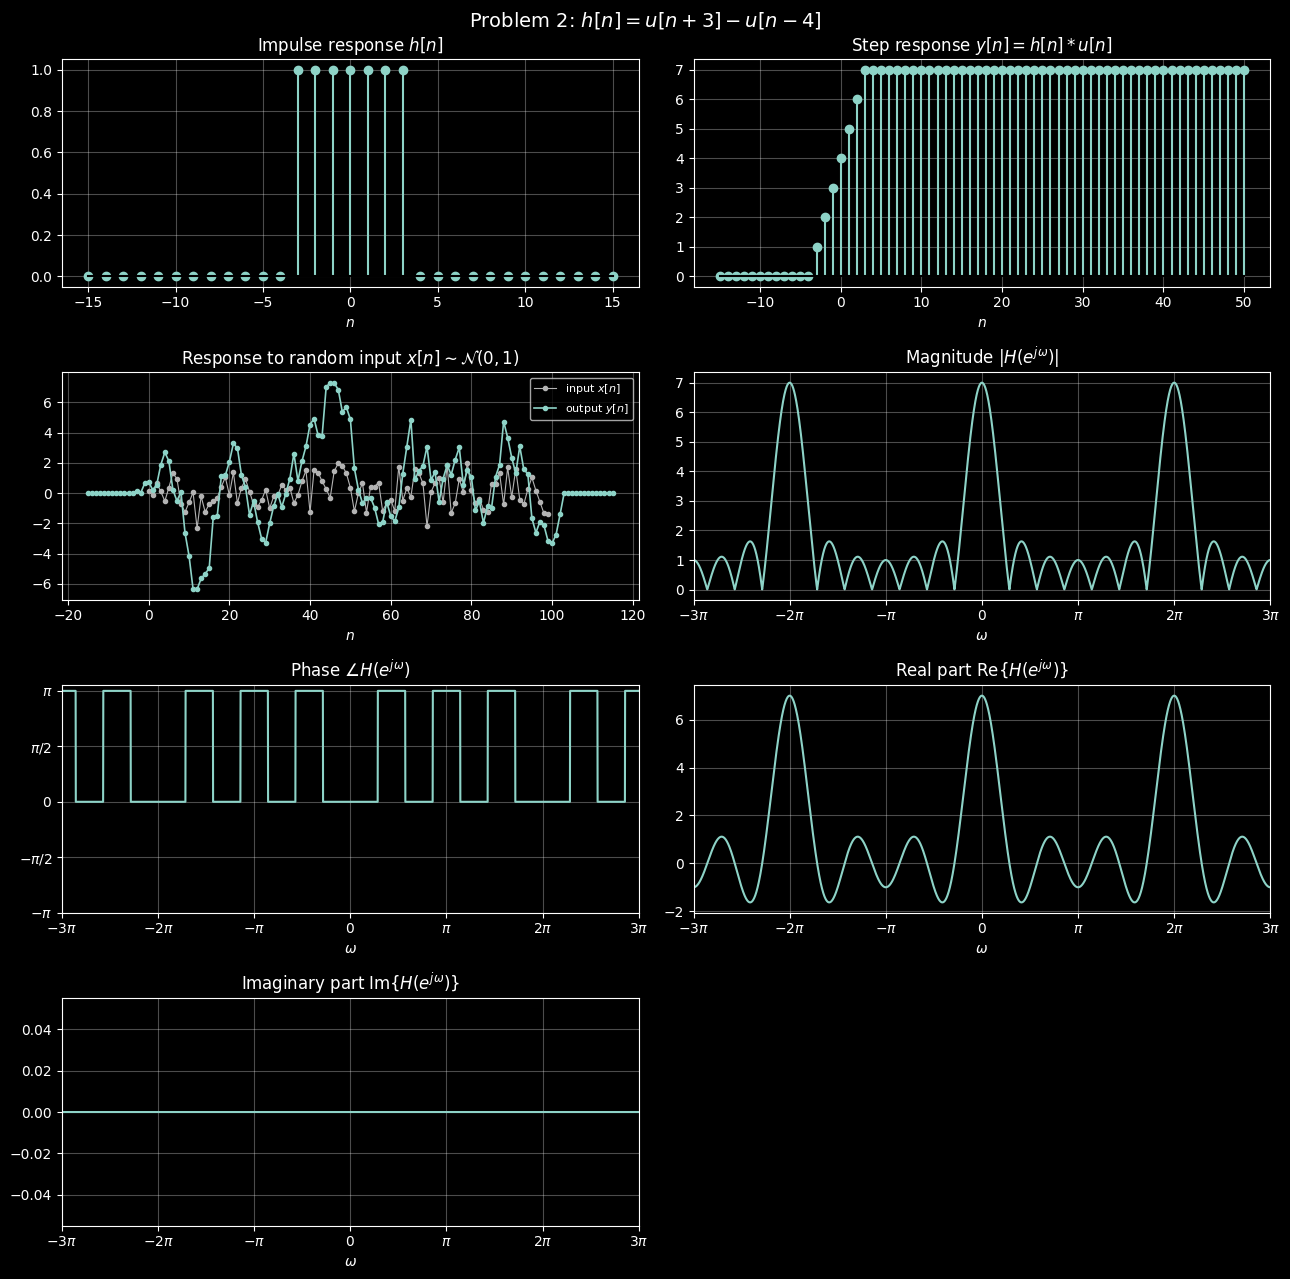

In [8]:
h2 = lambda n: u(n + 3) - u(n - 4)
ba2 = (np.ones(7), [1], -3)                  # FIR: 7 ones starting at n = -3

print("ba check:", verify_ba(h2, ba2))
analyze(h2, r"Problem 2: $h[n] = u[n+3] - u[n-4]$", ba2)
plt.show()

#### Classification

| Property        | Answer                           | Justification                                                                                                    |
|:----------------|:---------------------------------|:-----------------------------------------------------------------------------------------------------------------|
| **Filter type** | Lowpass                          | When I compare $\lvert H(e^{j\omega})\rvert$ at ω = 0 (DC) and ω = π, the peak is at ω = 0 and is small at ω = π |
| **Causality**   | Non-causal                       | There are samples such that $h[n] \neq 0$ for $n<0$                                                              |
| **Stability**   | Stable                           | $\Sigma{\lvert h[n] \rvert} =7 < \infty$                                                                         |
| **FIR or IIR**  | FIR                              | There are only 7 nonzero samples                                                                                 |

<!--
Filter type: compare |H(e^{jω})| at ω = 0 (DC) and ω = π, and look for peaks or notches in between.
  Lowpass: largest near 0, small near π.   Highpass: small near 0, largest near π.
  Bandpass: small at both 0 and π, peak in between.   Bandstop: large at 0 and π, notch in between.
Causality: causal if and only if h[n] = 0 for all n < 0 (check the impulse-response plot left of n = 0).
Stability (BIBO): stable if and only if Σ|h[n]| < ∞. For a rational H(z), equivalently all poles have |p| < 1.
  Also visible in the step response: it should settle to a finite value H(e^{j0}).
FIR vs IIR: FIR if h[n] has a finite number of nonzero samples, IIR otherwise.
-->

### Problem 3: $h[n] = \delta[n] - \delta[n-1] + \delta[n-2] - \delta[n-3]$

#### Derivation

**Step 1: Write out $h[n]$ sample by sample.**

Each $\delta[n-m]$ places a single sample at $n = m$, with the sign in front of it:

$$h[n] = \delta[n] - \delta[n-1] + \delta[n-2] - \delta[n-3]$$

| $n$ | $\le -1$ | $0$ | $1$ | $2$ | $3$ | $\ge 4$ |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| $h[n]$ | 0 | $1$  | $-1$ | $1$ | $-1$ | 0 |

Four taps with alternating signs. *(Impulse-response plot.)*

---

**Step 2: Output for any input $x[n]$.**

In the convolution sum $y[n] = \sum_k h[k]\,x[n-k]$, only $k = 0, 1, 2, 3$ survive, each weighted by its tap:

$$y[n] = (1)\,x[n] + (-1)\,x[n-1] + (1)\,x[n-2] + (-1)\,x[n-3] = x[n] - x[n-1] + x[n-2] - x[n-3]$$

Slowly changing inputs nearly cancel, since $+x - x + x - x \approx 0$, while inputs that alternate in sign add up. *(Random-input plot: the output is rougher than the input. Its variance is $1^2 + 1^2 + 1^2 + 1^2 = 4$, so its standard deviation is about 2.)*

---

**Step 3: Step response, $x[n] = u[n]$.**

The step response is the running sum of the taps, $s[n] = \sum_{k=-\infty}^{n} h[k]$:

| $n$ | $\le -1$ | $0$ | $1$ | $2$ | $\ge 3$ |
|:---:|:---:|:---:|:---:|:---:|:---:|
| running sum | 0 | $1$ | $1 - 1 = 0$ | $0 + 1 = 1$ | $1 - 1 = 0$ |

$$s[n] = \delta[n] + \delta[n-2]$$

The final value is 0 because the taps add up to 0. A constant (DC) input produces no output. *(Step-response plot: two unit spikes at $n = 0$ and $n = 2$, then 0.)*

---

**Step 4: Frequency response, written out term by term.**

Each tap $h[n]$ contributes $h[n]\,e^{-j\omega n}$:

$$H(e^{j\omega}) = \sum_{n=0}^{3} h[n]\,e^{-j\omega n} = 1 - e^{-j\omega} + e^{-j2\omega} - e^{-j3\omega}$$

Use $e^{-j\theta} = \cos\theta - j\sin\theta$ on every term to split real and imaginary parts:

$$\operatorname{Re}\{H\} = 1 - \cos\omega + \cos 2\omega - \cos 3\omega, \qquad
\operatorname{Im}\{H\} = \sin\omega - \sin 2\omega + \sin 3\omega$$

---

**Step 5: Closed form by factoring (explains the shape of the plots).**

Group the four terms in pairs and pull out the common factor:

$$H(e^{j\omega}) = \left(1 - e^{-j\omega}\right) + e^{-j2\omega}\left(1 - e^{-j\omega}\right) = \left(1 - e^{-j\omega}\right)\left(1 + e^{-j2\omega}\right)$$

Simplify each factor by pulling out half of its exponent:

$$\begin{aligned}
1 - e^{-j\omega} &= e^{-j\omega/2}\left(e^{j\omega/2} - e^{-j\omega/2}\right) = 2j\sin(\omega/2)\,e^{-j\omega/2} \\
1 + e^{-j2\omega} &= e^{-j\omega}\left(e^{j\omega} + e^{-j\omega}\right) = 2\cos(\omega)\,e^{-j\omega}
\end{aligned}$$

Multiply them back together:

$$\boxed{H(e^{j\omega}) = 4j\,\sin(\omega/2)\cos(\omega)\,e^{-j3\omega/2}}$$

Each factor accounts for part of the magnitude plot: $\sin(\omega/2)$ creates the zero at $\omega = 0$, and $\cos\omega$ creates the zeros at $\omega = \pm\pi/2$.

---

**Step 6: Magnitude, phase, real, and imaginary parts.**

Write $j = e^{j\pi/2}$ so all the phase terms are together:

$$H(e^{j\omega}) = \underbrace{4\sin(\omega/2)\cos\omega}_{\text{real amplitude}}\;e^{\,j\left(\frac{\pi}{2} - \frac{3\omega}{2}\right)}$$

$$|H(e^{j\omega})| = 4\,|\sin(\omega/2)\cos\omega|$$

$$\angle H(e^{j\omega}) = \begin{cases} \dfrac{\pi}{2} - \dfrac{3\omega}{2}, & \sin(\omega/2)\cos\omega > 0 \\[1ex] \dfrac{\pi}{2} - \dfrac{3\omega}{2} + \pi, & \sin(\omega/2)\cos\omega < 0 \end{cases} \quad \text{(then wrapped into } (-\pi, \pi]\text{)}$$

The real and imaginary parts are the ones from Step 4. The phase has a slope of $-3/2$, a 1.5-sample delay to the center of $h[n]$, plus a constant $\pi/2$ because $h[n]$ is antisymmetric about $n = 1.5$ ($h[0] = -h[3]$, $h[1] = -h[2]$).

---

**Step 7: Key values to check against the plots.**

| Quantity | Value | Where to see it |
|:---|:---|:---|
| $H(e^{j0})$ | $1 - 1 + 1 - 1 = 0$ | Magnitude is 0 at DC; step response ends at 0 |
| $H(e^{j\pi})$ | $1 + 1 + 1 + 1 = 4$ | Peak of magnitude and real part at $\omega = \pm\pi$ |
| Zeros of $H$ | $\omega = 0$ and $\cos\omega = 0 \Rightarrow \omega = \pm\tfrac{\pi}{2}$ | Magnitude touches 0 three times per period |
| Small humps | $\lvert H\rvert \approx 1.08$ near $\omega = \pm\tfrac{\pi}{4}$ | Between the zeros at $0$ and $\pm\tfrac{\pi}{2}$ |
| Phase slope | $-3/2$ (1.5-sample delay) | Descending segments in the phase plot |
| Period | $2\pi$ | Every frequency plot repeats at $\omega = \pm 2\pi$ |

ba check: 0.0


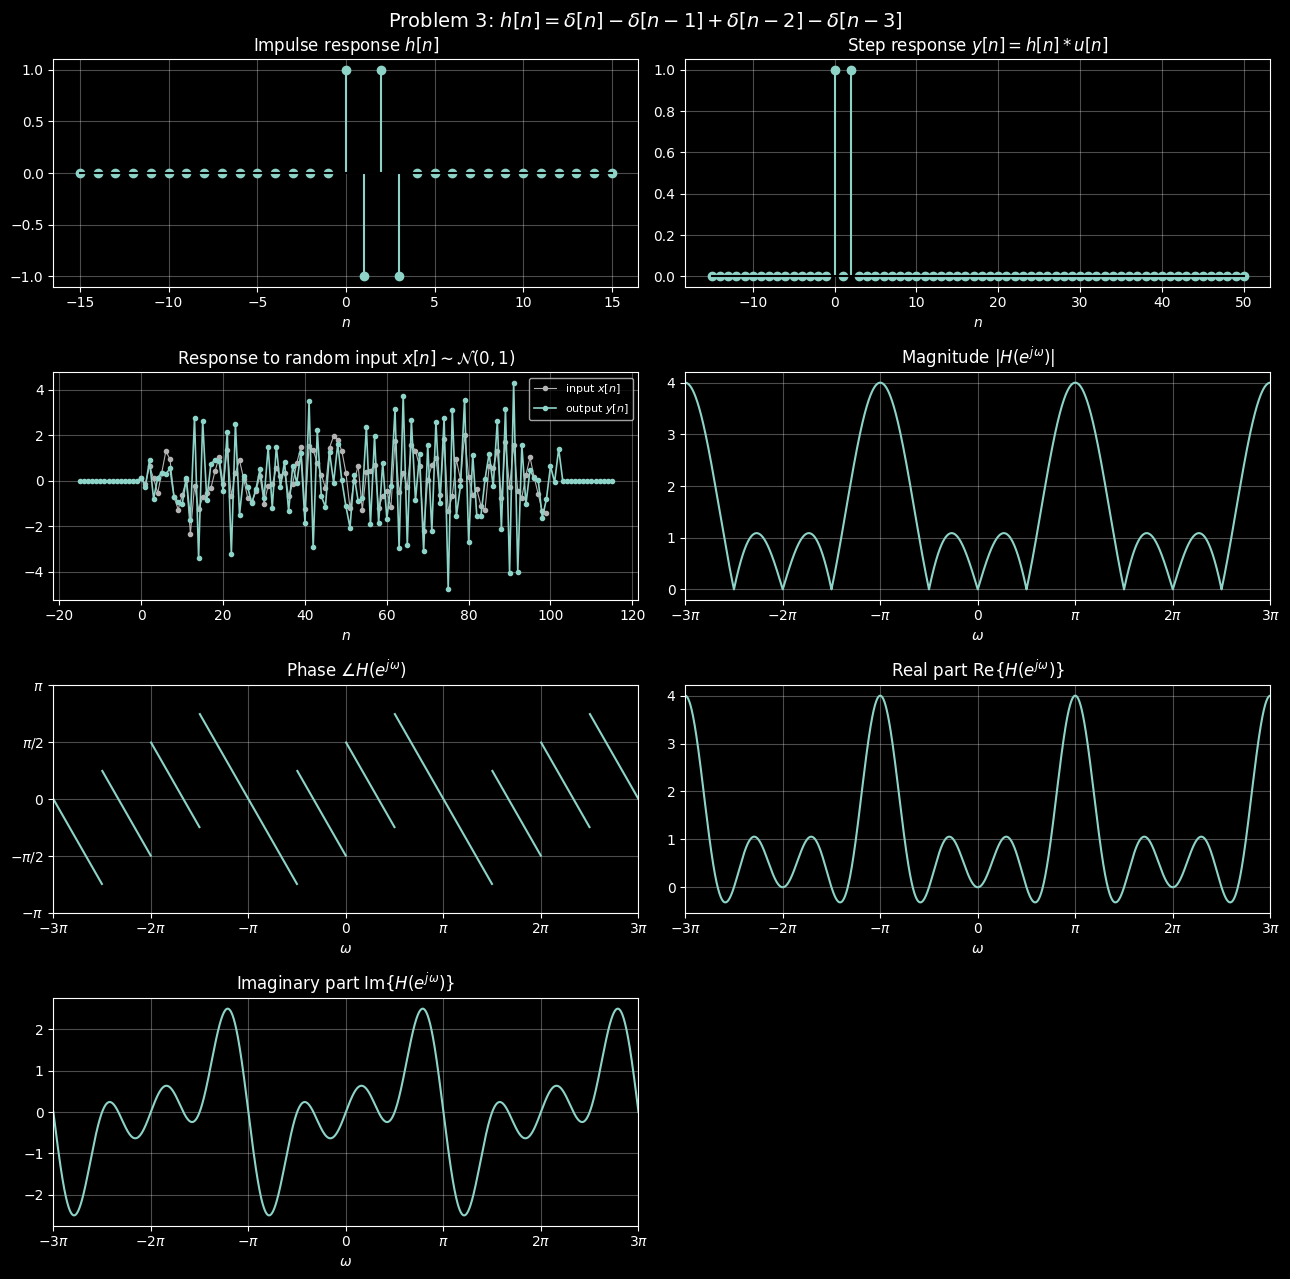

In [9]:
h3 = lambda n: delta(n) - delta(n - 1) + delta(n - 2) - delta(n - 3)
ba3 = ([1, -1, 1, -1], [1])

print("ba check:", verify_ba(h3, ba3))
analyze(h3, r"Problem 3: $h[n] = \delta[n] - \delta[n-1] + \delta[n-2] - \delta[n-3]$", ba3)
plt.show()

#### Classification

| Property        | Answer   | Justification                                                                                                        |
|:----------------|:---------|:---------------------------------------------------------------------------------------------------------------------|
| **Filter type** | Highpass | When I compare $\lvert H(e^{j\omega})\rvert$ at ω = 0 (DC) and ω = π, the peak is at ω = π and most minimum at ω = 0 |
| **Causality**   | Causal   | $h[n] = 0$ for all n < 0                                                                                             |
| **Stability**   | Stable   | $\Sigma \lvert h[n]\rvert = 1 + 1 + 1 + 1 = 4 < \infty$                                                              |
| **FIR or IIR**  | FIR      | There are only 4 nonzero samples.                                                                                    |

<!--
Filter type: compare |H(e^{jω})| at ω = 0 (DC) and ω = π, and look for peaks or notches in between.
  Lowpass: largest near 0, small near π.   Highpass: small near 0, largest near π.
  Bandpass: small at both 0 and π, peak in between.   Bandstop: large at 0 and π, notch in between.
Causality: causal if and only if h[n] = 0 for all n < 0 (check the impulse-response plot left of n = 0).
Stability (BIBO): stable if and only if Σ|h[n]| < ∞. For a rational H(z), equivalently all poles have |p| < 1.
  Also visible in the step response: it should settle to a finite value H(e^{j0}).
FIR vs IIR: FIR if h[n] has a finite number of nonzero samples, IIR otherwise.
-->

### Problem 4: $h[n] = \delta[n] + \delta[n-1] - \delta[n-2] - \delta[n-3]$

#### Derivation

**Step 1: Write out $h[n]$ sample by sample.**

$$h[n] = \delta[n] + \delta[n-1] - \delta[n-2] - \delta[n-3]$$

| $n$ | $\le -1$ | $0$ | $1$ | $2$ | $3$ | $\ge 4$ |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| $h[n]$ | 0 | 1 | 1 | $-1$ | $-1$ | 0 |

Two positive taps followed by two negative taps. *(Impulse-response plot.)*

---

**Step 2: Output for any input $x[n]$.**

In the convolution sum, only $k = 0, 1, 2, 3$ survive:

$$y[n] = x[n] + x[n-1] - x[n-2] - x[n-3] = \underbrace{\big(x[n] + x[n-1]\big)}_{\text{recent pair}} - \underbrace{\big(x[n-2] + x[n-3]\big)}_{\text{older pair}}$$

The output is the difference between the two most recent inputs and the two before them, which measures how much the input changed. *(Random-input plot: output standard deviation about 2.)*

---

**Step 3: Step response, $x[n] = u[n]$.**

Running sum of the taps:

| $n$ | $\le -1$ | $0$ | $1$ | $2$ | $\ge 3$ |
|:---:|:---:|:---:|:---:|:---:|:---:|
| running sum | 0 | $1$ | $1 + 1 = 2$ | $2 - 1 = 1$ | $1 - 1 = 0$ |

$$s[n] = \delta[n] + 2\delta[n-1] + \delta[n-2]$$

The final value is again 0, because the taps add up to 0. *(Step-response plot: values $1, 2, 1$, then 0.)*

---

**Step 4: Frequency response, written out term by term.**

$$H(e^{j\omega}) = 1 + e^{-j\omega} - e^{-j2\omega} - e^{-j3\omega}$$

Use $e^{-j\theta} = \cos\theta - j\sin\theta$ on every term:

$$\operatorname{Re}\{H\} = 1 + \cos\omega - \cos 2\omega - \cos 3\omega, \qquad
\operatorname{Im}\{H\} = -\sin\omega + \sin 2\omega + \sin 3\omega$$

---

**Step 5: Closed form by factoring (explains the shape of the plots).**

Group in pairs and pull out the common factor:

$$H(e^{j\omega}) = \left(1 + e^{-j\omega}\right) - e^{-j2\omega}\left(1 + e^{-j\omega}\right) = \left(1 + e^{-j\omega}\right)\left(1 - e^{-j2\omega}\right)$$

The second factor is a difference of squares, $1 - a^2 = (1-a)(1+a)$ with $a = e^{-j\omega}$:

$$H(e^{j\omega}) = \left(1 - e^{-j\omega}\right)\left(1 + e^{-j\omega}\right)^2$$

Simplify each factor:

$$\begin{aligned}
1 - e^{-j\omega} &= 2j\sin(\omega/2)\,e^{-j\omega/2} \\
\left(1 + e^{-j\omega}\right)^2 &= \left[2\cos(\omega/2)\,e^{-j\omega/2}\right]^2 = 4\cos^2(\omega/2)\,e^{-j\omega}
\end{aligned}$$

Multiply them back together:

$$\boxed{H(e^{j\omega}) = 8j\,\sin(\omega/2)\cos^2(\omega/2)\,e^{-j3\omega/2}}$$

$\sin(\omega/2)$ gives a single zero at $\omega = 0$, and $\cos^2(\omega/2)$ gives a double zero at $\omega = \pi$.

---

**Step 6: Magnitude, phase, real, and imaginary parts.**

$$H(e^{j\omega}) = \underbrace{8\sin(\omega/2)\cos^2(\omega/2)}_{\text{real amplitude}}\;e^{\,j\left(\frac{\pi}{2} - \frac{3\omega}{2}\right)}$$

$$|H(e^{j\omega})| = 8\,|\sin(\omega/2)|\cos^2(\omega/2)$$

$$\angle H(e^{j\omega}) = \begin{cases} \dfrac{\pi}{2} - \dfrac{3\omega}{2}, & \sin(\omega/2) > 0 \\[1ex] \dfrac{\pi}{2} - \dfrac{3\omega}{2} + \pi, & \sin(\omega/2) < 0 \end{cases} \quad \text{(then wrapped into } (-\pi, \pi]\text{)}$$

Since $\cos^2(\omega/2) \ge 0$, only $\sin(\omega/2)$ can change the sign. So the phase jumps by $\pi$ at $\omega = 0$ but only wraps at $\omega = \pi$.

**Peak of the magnitude.** Let $s = \sin(\omega/2)$, so $\cos^2(\omega/2) = 1 - s^2$ and $|H| = 8s(1 - s^2)$ for $s \ge 0$. Setting the derivative to zero:

$$\frac{d}{ds}\left[8s - 8s^3\right] = 8 - 24s^2 = 0 \;\Rightarrow\; s = \frac{1}{\sqrt{3}} \;\Rightarrow\; |H|_{\max} = 8\cdot\frac{1}{\sqrt3}\cdot\frac{2}{3} = \frac{16}{3\sqrt3} \approx 3.08$$

at $\omega = 2\arcsin(1/\sqrt3) \approx 0.39\pi$.

---

**Step 7: Key values to check against the plots.**

| Quantity | Value | Where to see it |
|:---|:---|:---|
| $H(e^{j0})$ | $1 + 1 - 1 - 1 = 0$ | Sharp V-shaped zero in the magnitude at DC |
| $H(e^{j\pi})$ | $1 - 1 - 1 + 1 = 0$ | Rounded, flat-bottomed zero at $\omega = \pm\pi$ (double zero) |
| Peak | $\lvert H\rvert_{\max} \approx 3.08$ at $\omega \approx \pm 0.39\pi$ | Two peaks per period in the magnitude plot |
| Phase slope | $-3/2$ (1.5-sample delay) | Descending segments in the phase plot |
| Period | $2\pi$ | Every frequency plot repeats at $\omega = \pm 2\pi$ |

ba check: 0.0


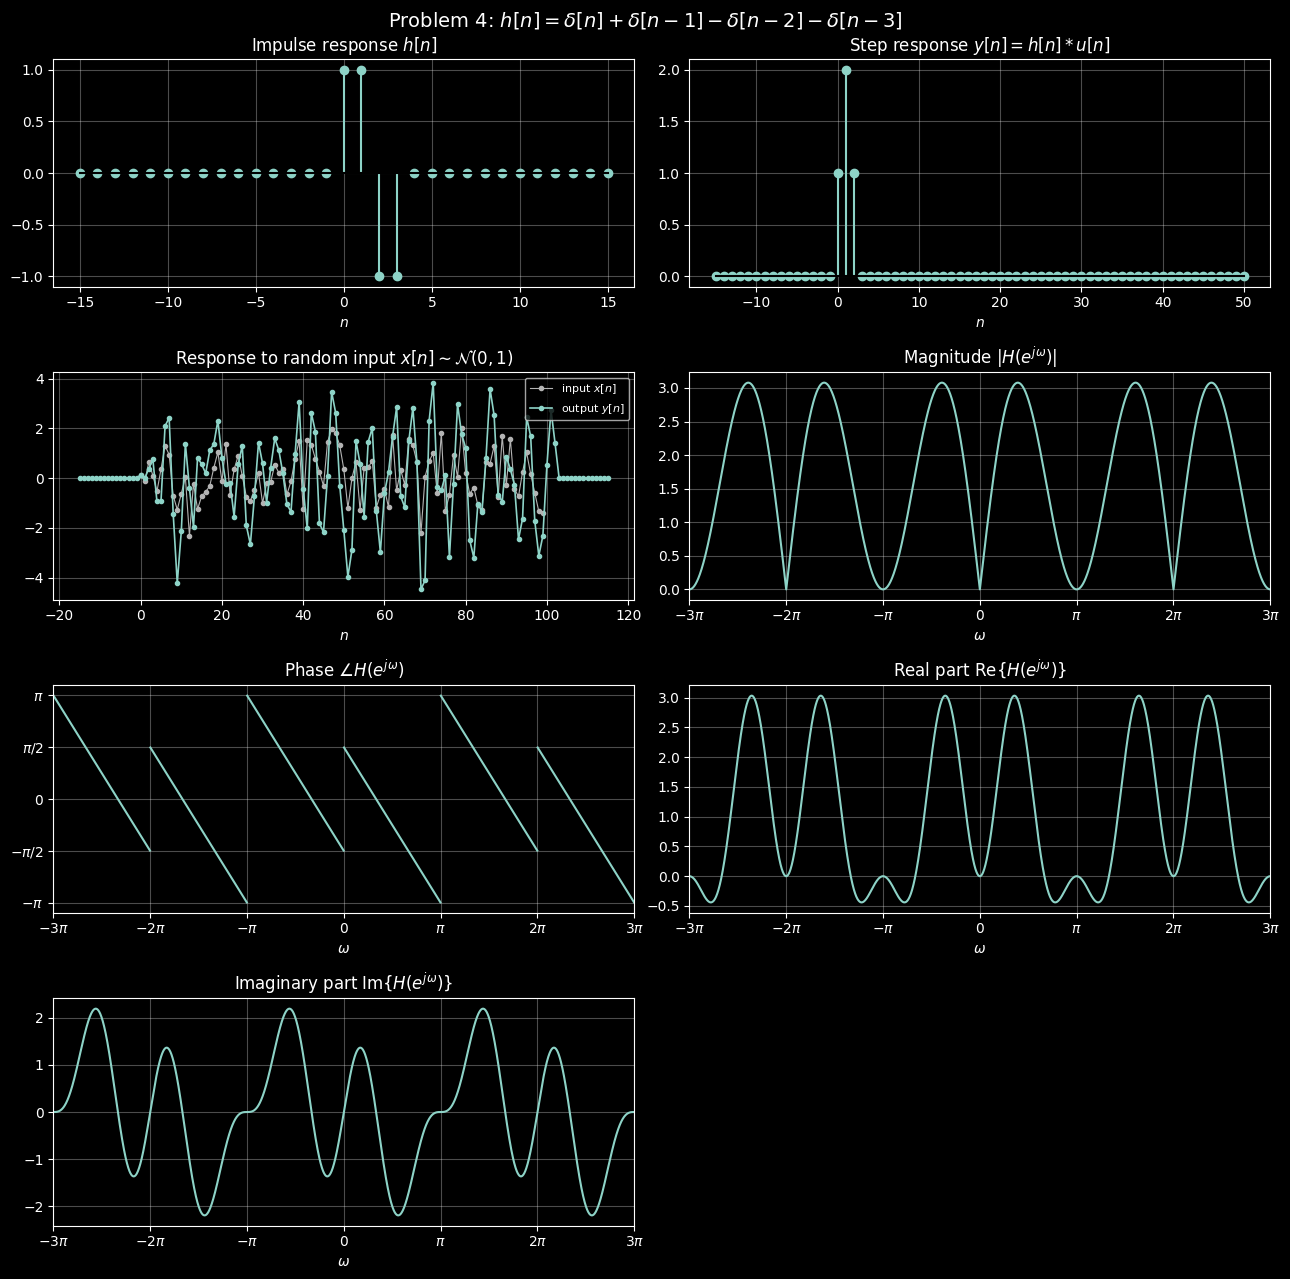

In [10]:
h4 = lambda n: delta(n) + delta(n - 1) - delta(n - 2) - delta(n - 3)
ba4 = ([1, 1, -1, -1], [1])

print("ba check:", verify_ba(h4, ba4))
analyze(h4, r"Problem 4: $h[n] = \delta[n] + \delta[n-1] - \delta[n-2] - \delta[n-3]$", ba4)
plt.show()

#### Classification

| Property        | Answer    | Justification                                                                                                                                                 |
|:----------------|:----------|:--------------------------------------------------------------------------------------------------------------------------------------------------------------|
| **Filter type** | Bandpass  | When I compare $\lvert H(e^{j\omega})\rvert$ at ω = 0 (DC) and ω = π, ω = π and ω = 0 are both maximally small with the peak at an angle somewhere in between |
| **Causality**   | Causal    | $h[n] = 0$ for all n < 0                                                                                                                                      |
| **Stability**   | Stable    | $\Sigma{\lvert h[n] \rvert} = 4 < \infty$                                                                                                                     |
| **FIR or IIR**  | FIR       | There are only 4 nonzero samples                                                                                                                              |

<!--
Filter type: compare |H(e^{jω})| at ω = 0 (DC) and ω = π, and look for peaks or notches in between.
  Lowpass: largest near 0, small near π.   Highpass: small near 0, largest near π.
  Bandpass: small at both 0 and π, peak in between.   Bandstop: large at 0 and π, notch in between.
Causality: causal if and only if h[n] = 0 for all n < 0 (check the impulse-response plot left of n = 0).
Stability (BIBO): stable if and only if Σ|h[n]| < ∞. For a rational H(z), equivalently all poles have |p| < 1.
  Also visible in the step response: it should settle to a finite value H(e^{j0}).
FIR vs IIR: FIR if h[n] has a finite number of nonzero samples, IIR otherwise.
-->

### Problem 5: $h[n] = 0.8^{n}\,u[n]$

#### Derivation

**Step 1: Write out $h[n]$ sample by sample.**

$u[n]$ turns the sequence on at $n = 0$. Each sample is $0.8$ times the one before it:

| $n$ | $\le -1$ | $0$ | $1$ | $2$ | $3$ | $4$ | $5$ | $\cdots$ |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| $h[n] = 0.8^n$ | 0 | 1 | 0.8 | 0.64 | 0.512 | 0.410 | 0.328 | $\to 0$ |

The response decays toward zero but never reaches it, so $h[n]$ is infinitely long. *(Impulse-response plot.)*

---

**Step 2: Output for any input $x[n]$, as a recursion.**

From the convolution sum, with $h[k] = 0.8^k$ for $k \ge 0$:

$$y[n] = \sum_{k=0}^{\infty} 0.8^k\,x[n-k] = x[n] + \sum_{k=1}^{\infty} 0.8^k\,x[n-k]$$

In the remaining sum, factor out one $0.8$ and substitute $k' = k - 1$:

$$\sum_{k=1}^{\infty} 0.8^k\,x[n-k] = 0.8\sum_{k'=0}^{\infty} 0.8^{k'}\,x[(n-1)-k'] = 0.8\,y[n-1]$$

So the infinite sum collapses to a one-line recursion:

$$\boxed{y[n] = 0.8\,y[n-1] + x[n]}$$

Each output is the new input plus 80% of the previous output, which averages the input over time. *(Random-input plot: a smoothed input. After the input stops at $n = 99$, the output decays by a factor of 0.8 each step instead of stopping.)*

---

**Step 3: Step response, $x[n] = u[n]$.**

$s[n] = \sum_{k=0}^{n} h[k]$ is a finite geometric series with ratio $0.8$:

$$s[n] = \sum_{k=0}^{n} 0.8^k = \frac{1 - 0.8^{n+1}}{1 - 0.8} = 5\left(1 - 0.8^{n+1}\right), \quad n \ge 0$$

| $n$ | $0$ | $1$ | $2$ | $3$ | $\cdots$ | $\infty$ |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| $s[n]$ | 1 | 1.8 | 2.44 | 2.95 | $\cdots$ | 5 |

*(Step-response plot: rises smoothly and settles at 5.)*

---

**Step 4: Frequency response.**

$$H(e^{j\omega}) = \sum_{n=0}^{\infty} 0.8^n e^{-j\omega n} = \sum_{n=0}^{\infty}\left(0.8\,e^{-j\omega}\right)^n$$

This is an infinite geometric series with ratio $a = 0.8\,e^{-j\omega}$. Since $|a| = 0.8 < 1$, it converges to $\dfrac{1}{1-a}$:

$$\boxed{H(e^{j\omega}) = \frac{1}{1 - 0.8\,e^{-j\omega}}}$$

---

**Step 5: Separate the real and imaginary parts.**

Expand the denominator with $e^{-j\omega} = \cos\omega - j\sin\omega$:

$$1 - 0.8\,e^{-j\omega} = (1 - 0.8\cos\omega) + j\,0.8\sin\omega$$

Multiply the top and bottom by the conjugate, $(1 - 0.8\cos\omega) - j\,0.8\sin\omega$. The denominator becomes real:

$$(1 - 0.8\cos\omega)^2 + (0.8\sin\omega)^2 = 1 - 1.6\cos\omega + 0.64\left(\cos^2\omega + \sin^2\omega\right) = 1.64 - 1.6\cos\omega$$

$$H(e^{j\omega}) = \frac{(1 - 0.8\cos\omega) - j\,0.8\sin\omega}{1.64 - 1.6\cos\omega}$$

---

**Step 6: Magnitude, phase, real, and imaginary parts.**

$$\operatorname{Re}\{H\} = \frac{1 - 0.8\cos\omega}{1.64 - 1.6\cos\omega}, \qquad
\operatorname{Im}\{H\} = \frac{-0.8\sin\omega}{1.64 - 1.6\cos\omega}$$

$$|H(e^{j\omega})| = \frac{1}{|1 - 0.8e^{-j\omega}|} = \frac{1}{\sqrt{1.64 - 1.6\cos\omega}}, \qquad
\angle H(e^{j\omega}) = -\arctan\!\left(\frac{0.8\sin\omega}{1 - 0.8\cos\omega}\right)$$

Since $1 - 0.8\cos\omega \ge 0.2 > 0$, the real part is always positive. The phase therefore never reaches $\pm\pi/2$ and needs no wrapping.

---

**Step 7: Key values to check against the plots.**

| Quantity | Value | Where to see it |
|:---|:---|:---|
| $H(e^{j0})$ | $\dfrac{1}{1 - 0.8} = 5$ | Peak of magnitude and real part; final value of the step response |
| $H(e^{j\pi})$ | $\dfrac{1}{1 + 0.8} \approx 0.556$ | Minimum of magnitude and real part at $\omega = \pm\pi$ |
| Phase extremes | $\pm\arctan(4/3) = \pm 0.295\pi$ at $\omega \approx \mp 0.205\pi$ | Phase plot; it never wraps |
| $\operatorname{Im}\{H\}$ extremes | $\pm 2.22$ at $\omega \approx \mp 0.07\pi$ | Sharp swing in the imaginary part around DC |
| Pole | $z = 0.8$, inside the unit circle | Why the geometric series converges |
| Period | $2\pi$ | Every frequency plot repeats at $\omega = \pm 2\pi$ |

ba check: 5.551115123125783e-17


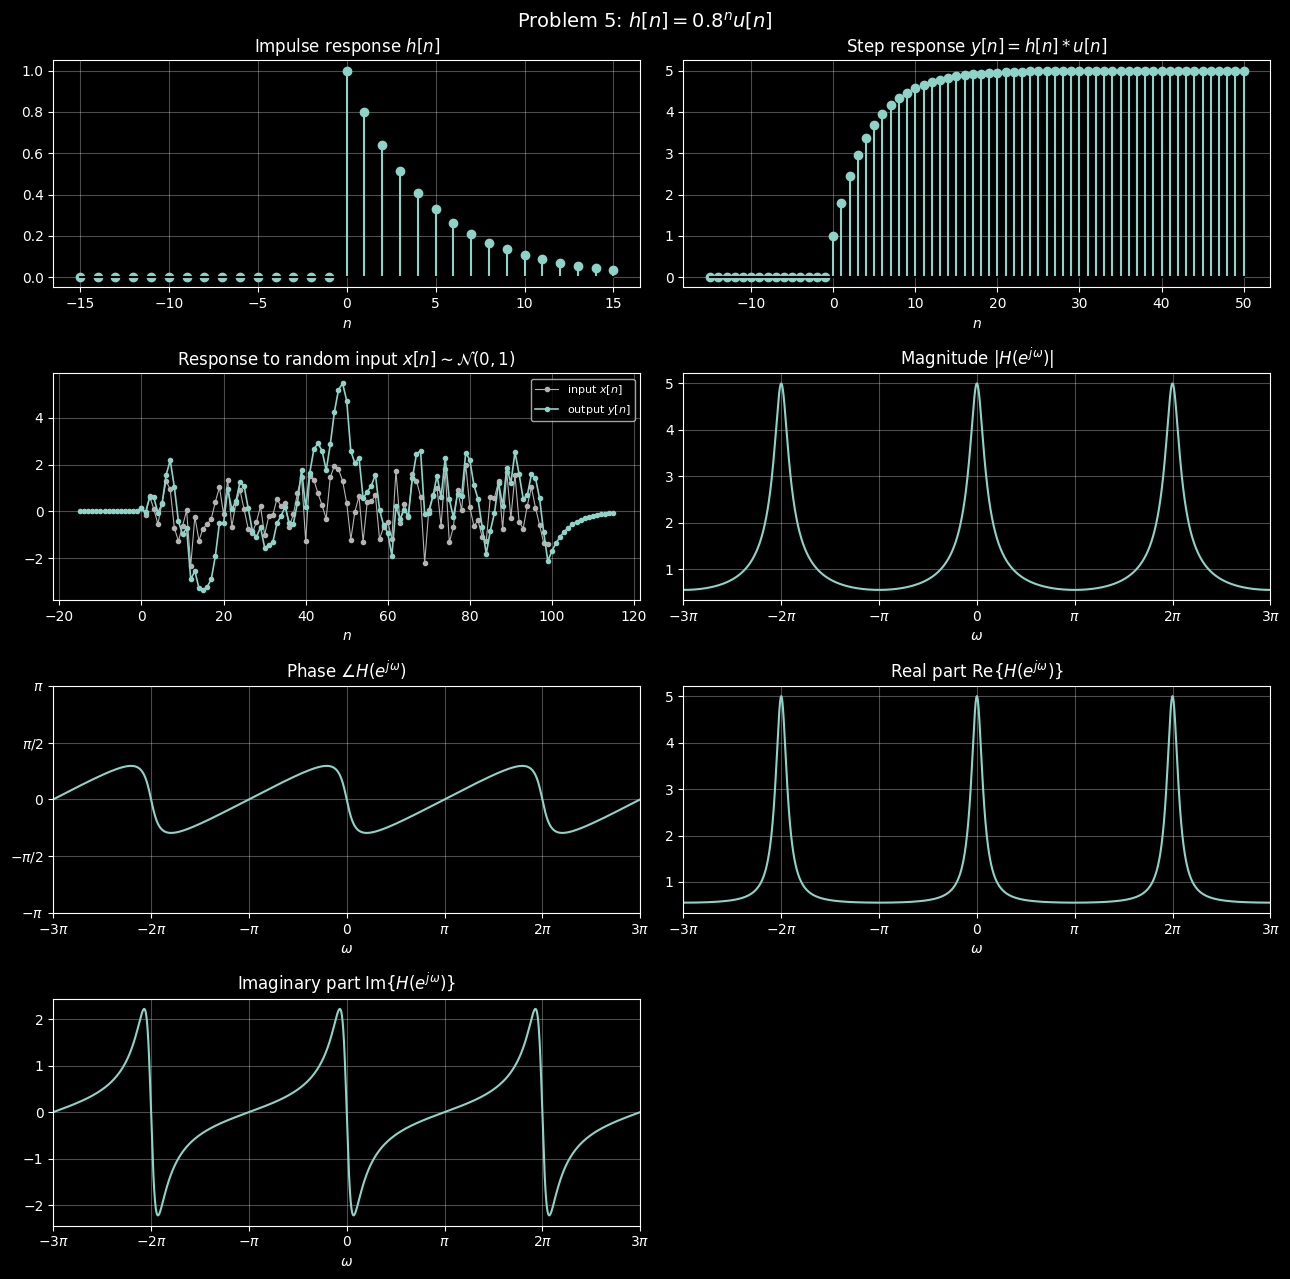

In [11]:
h5 = lambda n: 0.8**n * u(n)
ba5 = ([1], [1, -0.8])                       # y[n] = 0.8 y[n-1] + x[n]

print("ba check:", verify_ba(h5, ba5))
analyze(h5, r"Problem 5: $h[n] = 0.8^n u[n]$", ba5)
plt.show()

#### Classification

| Property        | Answer  | Justification                                                                                                        |
|:----------------|:--------|:---------------------------------------------------------------------------------------------------------------------|
| **Filter type** | Lowpass | When I compare $\lvert H(e^{j\omega})\rvert$ at ω = 0 (DC) and ω = π, the peak is at ω = 0 and most minimum at ω = π |
| **Causality**   | Causal  | $h[n] = 0$ for all n < 0                                                                                             |
| **Stability** | Stable  | $\Sigma{\lvert h[n] \rvert} = 5 < \infty$                                                                            |
| **FIR or IIR** | IIR     | There are an infinite number of nonzero samples                                                                      |

<!--
Filter type: compare |H(e^{jω})| at ω = 0 (DC) and ω = π, and look for peaks or notches in between.
  Lowpass: largest near 0, small near π.   Highpass: small near 0, largest near π.
  Bandpass: small at both 0 and π, peak in between.   Bandstop: large at 0 and π, notch in between.
Causality: causal if and only if h[n] = 0 for all n < 0 (check the impulse-response plot left of n = 0).
Stability (BIBO): stable if and only if Σ|h[n]| < ∞. For a rational H(z), equivalently all poles have |p| < 1.
  Also visible in the step response: it should settle to a finite value H(e^{j0}).
FIR vs IIR: FIR if h[n] has a finite number of nonzero samples, IIR otherwise.
-->

### Problem 6: $h[n] = (-0.8)^{n}\,u[n]$

#### Derivation

**Step 1: Write out $h[n]$ sample by sample.**

Each sample is $-0.8$ times the one before it, so the sign alternates while the size decays:

| $n$ | $\le -1$ | $0$ | $1$ | $2$ | $3$ | $4$ | $5$ | $\cdots$ |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| $h[n] = (-0.8)^n$ | 0 | 1 | $-0.8$ | 0.64 | $-0.512$ | 0.410 | $-0.328$ | $\to 0$ |

This equals Problem 5's $h[n]$ multiplied by $(-1)^n$. *(Impulse-response plot.)*

---

**Step 2: Output for any input $x[n]$, as a recursion.**

The same steps as Problem 5, with $0.8$ replaced by $-0.8$:

$$y[n] = \sum_{k=0}^{\infty}(-0.8)^k\,x[n-k] = x[n] + (-0.8)\sum_{k'=0}^{\infty}(-0.8)^{k'}\,x[(n-1)-k']$$

$$\boxed{y[n] = -0.8\,y[n-1] + x[n]}$$

Each output subtracts 80% of the previous output, so consecutive outputs push in opposite directions. *(Random-input plot: a jagged output that flips sign often. After $n = 99$ it decays while alternating sign.)*

---

**Step 3: Step response, $x[n] = u[n]$.**

A finite geometric series with ratio $-0.8$:

$$s[n] = \sum_{k=0}^{n}(-0.8)^k = \frac{1 - (-0.8)^{n+1}}{1 - (-0.8)} = \frac{5}{9}\left(1 - (-0.8)^{n+1}\right), \quad n \ge 0$$

| $n$ | $0$ | $1$ | $2$ | $3$ | $4$ | $\cdots$ | $\infty$ |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| $s[n]$ | 1 | 0.2 | 0.84 | 0.328 | 0.738 | $\cdots$ | $5/9 \approx 0.556$ |

*(Step-response plot: overshoots and undershoots alternately, then settles at 0.556.)*

---

**Step 4: Frequency response.**

An infinite geometric series with ratio $a = -0.8\,e^{-j\omega}$, where $|a| = 0.8 < 1$:

$$H(e^{j\omega}) = \sum_{n=0}^{\infty}\left(-0.8\,e^{-j\omega}\right)^n = \boxed{\frac{1}{1 + 0.8\,e^{-j\omega}}}$$

---

**Step 5: Separate the real and imaginary parts.**

$$1 + 0.8\,e^{-j\omega} = (1 + 0.8\cos\omega) - j\,0.8\sin\omega$$

Multiply the top and bottom by the conjugate, $(1 + 0.8\cos\omega) + j\,0.8\sin\omega$:

$$(1 + 0.8\cos\omega)^2 + (0.8\sin\omega)^2 = 1.64 + 1.6\cos\omega$$

$$H(e^{j\omega}) = \frac{(1 + 0.8\cos\omega) + j\,0.8\sin\omega}{1.64 + 1.6\cos\omega}$$

---

**Step 6: Magnitude, phase, real, and imaginary parts.**

$$\operatorname{Re}\{H\} = \frac{1 + 0.8\cos\omega}{1.64 + 1.6\cos\omega}, \qquad
\operatorname{Im}\{H\} = \frac{0.8\sin\omega}{1.64 + 1.6\cos\omega}$$

$$|H(e^{j\omega})| = \frac{1}{\sqrt{1.64 + 1.6\cos\omega}}, \qquad
\angle H(e^{j\omega}) = \arctan\!\left(\frac{0.8\sin\omega}{1 + 0.8\cos\omega}\right)$$

**Connection to Problem 5.** Since $(-1)^n = e^{j\pi n}$, we have $h_6[n] = e^{j\pi n}\,h_5[n]$. Multiplying by $e^{j\pi n}$ shifts the spectrum by $\pi$:

$$H_6(e^{j\omega}) = \sum_n h_5[n]\,e^{j\pi n}e^{-j\omega n} = \sum_n h_5[n]\,e^{-j(\omega - \pi)n} = H_5\!\left(e^{j(\omega - \pi)}\right)$$

Every frequency plot is Problem 5's, slid over by $\pi$.

---

**Step 7: Key values to check against the plots.**

| Quantity | Value | Where to see it |
|:---|:---|:---|
| $H(e^{j0})$ | $\dfrac{1}{1 + 0.8} \approx 0.556$ | Minimum of magnitude at DC; final value of the step response |
| $H(e^{j\pi})$ | $\dfrac{1}{1 - 0.8} = 5$ | Peak of magnitude and real part at $\omega = \pm\pi$ |
| Phase extremes | $\pm 0.295\pi$ at $\omega \approx \pm 0.795\pi$ | Just before and after the steep drop through $\omega = \pm\pi$ |
| $\operatorname{Im}\{H\}$ extremes | $\pm 2.22$ at $\omega \approx \pm 0.93\pi$ | Sharp swing in the imaginary part around $\pm\pi$ |
| Pole | $z = -0.8$, inside the unit circle | Why the geometric series converges |
| Period | $2\pi$ | Every frequency plot repeats at $\omega = \pm 2\pi$ |

ba check: 5.551115123125783e-17


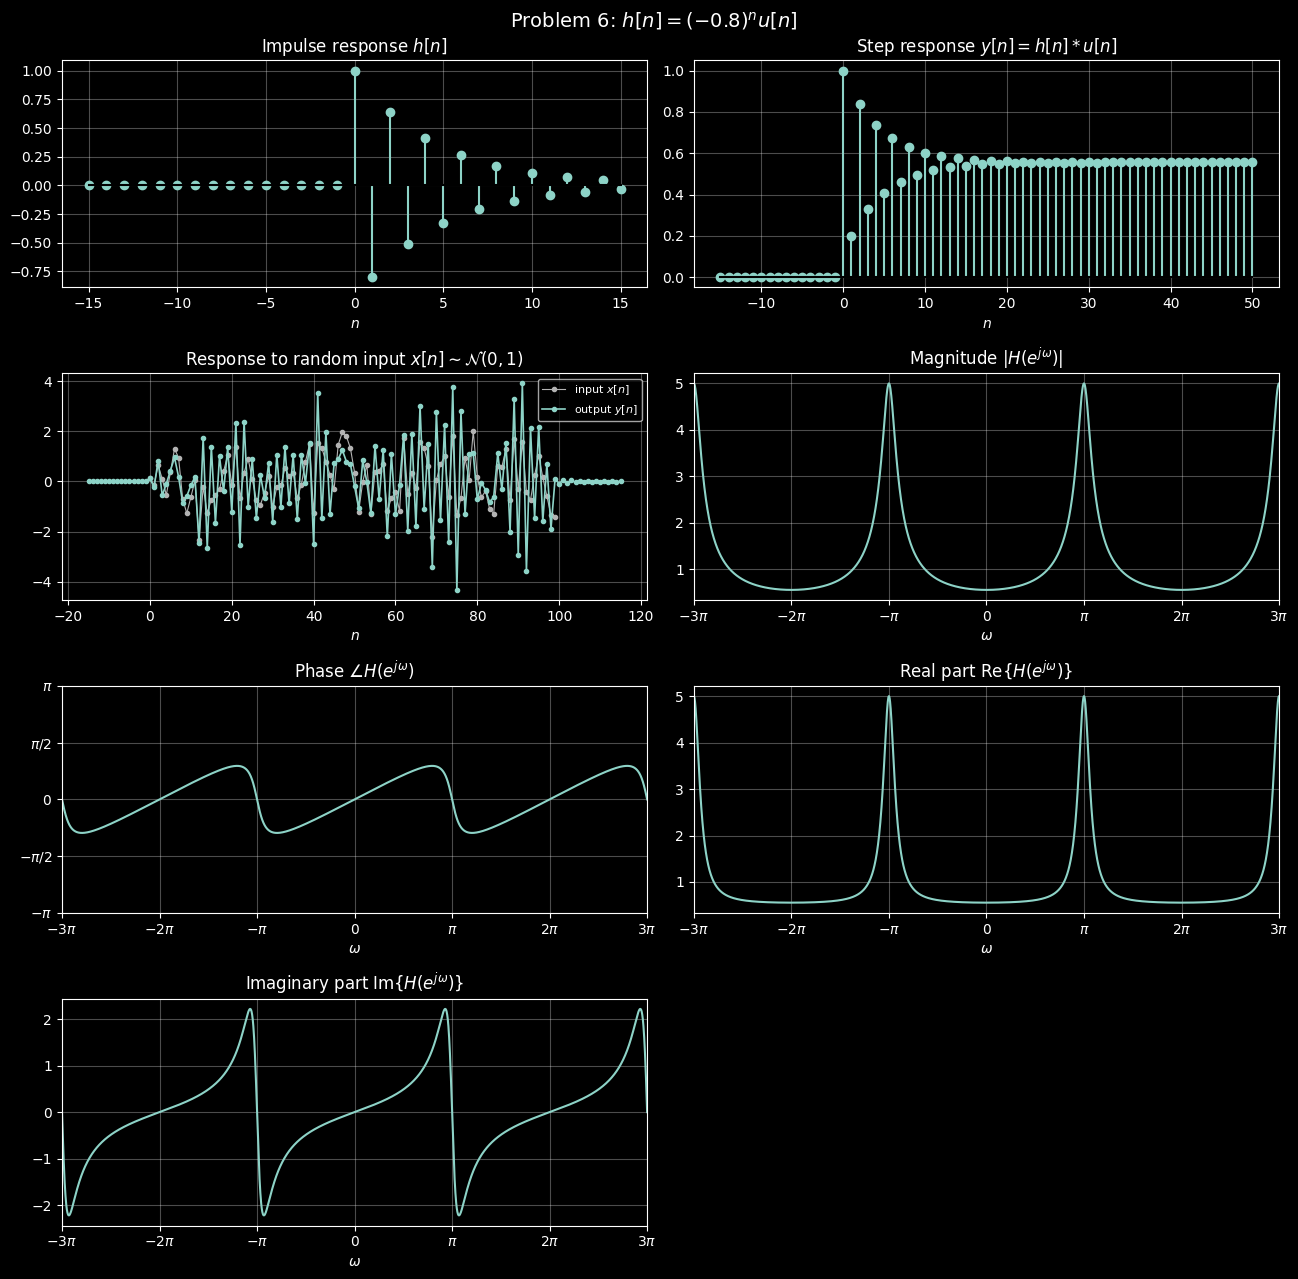

In [12]:
h6 = lambda n: (-0.8)**n * u(n)
ba6 = ([1], [1, 0.8])                        # y[n] = -0.8 y[n-1] + x[n]

print("ba check:", verify_ba(h6, ba6))
analyze(h6, r"Problem 6: $h[n] = (-0.8)^n u[n]$", ba6)
plt.show()

#### Classification

| Property        | Answer   | Justification                                                                                                        |
|:----------------|:---------|:---------------------------------------------------------------------------------------------------------------------|
| **Filter type** | Highpass | When I compare $\lvert H(e^{j\omega})\rvert$ at ω = 0 (DC) and ω = π, the peak is at ω = π and most minimum at ω = 0 |
| **Causality**   | Causal   | $h[n] = 0$ for all n < 0                                                                                             |
| **Stability**   | Stable   | $\Sigma \lvert(-0.8)^n\rvert = \sum_n 0.8^n = 5 < \infty$                                                            |
| **FIR or IIR**  | IIR      | There are an infinite number of nonzero samples                                                                      |

<!--
Filter type: compare |H(e^{jω})| at ω = 0 (DC) and ω = π, and look for peaks or notches in between.
  Lowpass: largest near 0, small near π.   Highpass: small near 0, largest near π.
  Bandpass: small at both 0 and π, peak in between.   Bandstop: large at 0 and π, notch in between.
Causality: causal if and only if h[n] = 0 for all n < 0 (check the impulse-response plot left of n = 0).
Stability (BIBO): stable if and only if Σ|h[n]| < ∞. For a rational H(z), equivalently all poles have |p| < 1.
  Also visible in the step response: it should settle to a finite value H(e^{j0}).
FIR vs IIR: FIR if h[n] has a finite number of nonzero samples, IIR otherwise.
-->

### Problem 7: $h[n] = 0.5\,(0.9^{n})\cos(0.3\pi n + 0.9\pi)\,u[n]$

#### Derivation

Constants: $r = 0.9$, $\omega_0 = 0.3\pi$, $\phi = 0.9\pi$, so $h[n] = 0.5\,r^n\cos(\omega_0 n + \phi)\,u[n]$.

**Step 1: Write out $h[n]$ sample by sample.**

| $n$ | $\le -1$ | $0$ | $1$ | $2$ | $3$ | $4$ | $5$ | $6$ | $7$ | $\cdots$ |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| $h[n]$ | 0 | $-0.476$ | $-0.364$ | 0 | 0.295 | 0.312 | 0.091 | $-0.156$ | $-0.239$ | $\to 0$ |

The cosine has period $2\pi/(0.3\pi) = 6.\overline{6}$ samples, and the factor $0.9^n$ shrinks it. The sample at $n = 2$ is exactly 0 because $\cos(0.6\pi + 0.9\pi) = \cos(1.5\pi) = 0$. *(Impulse-response plot.)*

---

**Step 2: Rewrite the cosine with Euler's formula.**

Use $\cos\theta = \dfrac{e^{j\theta} + e^{-j\theta}}{2}$ with $\theta = \omega_0 n + \phi$:

$$h[n] = \frac{0.5\,r^n}{2}\left[e^{j(\omega_0 n + \phi)} + e^{-j(\omega_0 n + \phi)}\right]u[n] = \frac14\left[e^{j\phi}\left(re^{j\omega_0}\right)^n + e^{-j\phi}\left(re^{-j\omega_0}\right)^n\right]u[n]$$

Name the complex pole $p = re^{j\omega_0} = 0.9\,e^{j0.3\pi}$, with conjugate $p^* = 0.9\,e^{-j0.3\pi}$:

$$h[n] = \frac14\left[e^{j\phi}\,p^n + e^{-j\phi}\,(p^*)^n\right]u[n]$$

The damped cosine is now a sum of two geometric sequences, each of which can be summed in closed form.

---

**Step 3: Frequency response.**

Each term is an infinite geometric series with ratio $p\,e^{-j\omega}$ or $p^*e^{-j\omega}$. Both have magnitude $0.9 < 1$, so both converge:

$$H(e^{j\omega}) = \frac14 e^{j\phi}\sum_{n=0}^{\infty}\left(p\,e^{-j\omega}\right)^n + \frac14 e^{-j\phi}\sum_{n=0}^{\infty}\left(p^*e^{-j\omega}\right)^n
= \frac{\tfrac14 e^{j\phi}}{1 - p\,e^{-j\omega}} + \frac{\tfrac14 e^{-j\phi}}{1 - p^*e^{-j\omega}}$$

Combine over a common denominator. Since $p + p^* = 2r\cos\omega_0$ and $pp^* = r^2$, the denominator is

$$\left(1 - p\,e^{-j\omega}\right)\left(1 - p^*e^{-j\omega}\right) = 1 - 2r\cos\omega_0\,e^{-j\omega} + r^2e^{-j2\omega}$$

and the numerator, after pairing the conjugate terms with Euler's formula, is

$$\tfrac14\left[e^{j\phi}\left(1 - p^*e^{-j\omega}\right) + e^{-j\phi}\left(1 - p\,e^{-j\omega}\right)\right] = \tfrac12\left[\cos\phi - r\cos(\phi - \omega_0)\,e^{-j\omega}\right]$$

Plug in the numbers: $\cos(0.9\pi) = -0.9511$, $r\cos(0.6\pi) = -0.2781$, $2r\cos(0.3\pi) = 1.0580$, and $r^2 = 0.81$:

$$\boxed{H(e^{j\omega}) = \frac{-0.4755 + 0.1391\,e^{-j\omega}}{1 - 1.0580\,e^{-j\omega} + 0.81\,e^{-j2\omega}}}$$

---

**Step 4: Output for any input $x[n]$ (difference equation).**

Write $H = B/A$ and cross-multiply, $A\,Y = B\,X$. Each $e^{-jk\omega}$ becomes a delay of $k$ samples:

$$y[n] - 1.0580\,y[n-1] + 0.81\,y[n-2] = -0.4755\,x[n] + 0.1391\,x[n-1]$$

$$\boxed{y[n] = 1.0580\,y[n-1] - 0.81\,y[n-2] - 0.4755\,x[n] + 0.1391\,x[n-1]}$$

The two feedback terms make the output ring at $\omega_0 = 0.3\pi$. *(Random-input plot: the output looks like a noisy oscillation with a period of about 6.7 samples, and it keeps ringing after the input stops at $n = 99$.)*

---

**Step 5: Step response, $x[n] = u[n]$.**

Since $h[n] = \operatorname{Re}\{0.5\,e^{j\phi}p^n\}$ for $n \ge 0$, the running sum is the real part of a finite geometric series:

$$s[n] = \sum_{k=0}^{n} h[k] = \operatorname{Re}\left\{0.5\,e^{j\phi}\sum_{k=0}^{n} p^k\right\} = \operatorname{Re}\left\{\frac{0.5\,e^{j\phi}}{1 - p}\left(1 - p^{\,n+1}\right)\right\}$$

With $C = \dfrac{0.5\,e^{j\phi}}{1 - p} = 0.577\,e^{-j0.783\pi}$, so that $\operatorname{Re}\{C\} = -0.447$:

$$s[n] = \underbrace{-0.447}_{\text{final value}} - \underbrace{0.577\,(0.9)^{n+1}\cos\!\big(0.3\pi(n+1) - 0.783\pi\big)}_{\text{decaying ring}}, \quad n \ge 0$$

*(Step-response plot: it starts at $s[0] = h[0] = -0.476$, rings, and settles at $-0.447$.)*

---

**Step 6: Magnitude, phase, real, and imaginary parts.**

With $H = B/A$:

$$|H| = \frac{|B|}{|A|}, \qquad \angle H = \angle B - \angle A, \qquad
\operatorname{Re}\{H\} = \frac{\operatorname{Re}\{B A^*\}}{|A|^2}, \qquad
\operatorname{Im}\{H\} = \frac{\operatorname{Im}\{B A^*\}}{|A|^2}$$

**Why the peaks are at $\pm 0.3\pi$.** The denominator factors into two distances:

$$|A| = \left|1 - p\,e^{-j\omega}\right|\left|1 - p^*e^{-j\omega}\right| = \left|e^{j\omega} - p\right|\left|e^{j\omega} - p^*\right|$$

Each factor is the distance from the point $e^{j\omega}$ on the unit circle to a pole. When $\omega = 0.3\pi$, the point $e^{j\omega}$ is directly next to $p = 0.9\,e^{j0.3\pi}$, a distance of only $1 - 0.9 = 0.1$. A small denominator gives a large $\lvert H\rvert$. Moving the poles closer to the unit circle would make the peak taller and narrower.

---

**Step 7: Key values to check against the plots.**

| Quantity | Value | Where to see it |
|:---|:---|:---|
| $H(e^{j0})$ | $\dfrac{-0.4755 + 0.1391}{1 - 1.0580 + 0.81} = -0.447$ | Dip between the two peaks; final value of the step response |
| $H(e^{j\pi})$ | $\dfrac{-0.4755 - 0.1391}{1 + 1.0580 + 0.81} = -0.214$ | Floor of the magnitude at $\omega = \pm\pi$ |
| Peak | $H(e^{j0.3\pi}) \approx -2.53 + 0.82j = 2.66\,e^{j0.90\pi}$ | Magnitude peaks at $\pm 0.3\pi$ |
| $\operatorname{Re}\{H\}$ | Negative for every $\omega$; minimum $\approx -2.59$ near $\pm 0.3\pi$ | Real-part plot; keeps the phase near $\pm\pi$ |
| $\operatorname{Im}\{H\}$ extremes | $+1.63$ at $0.324\pi$, $-0.72$ at $0.255\pi$ (mirrored for $\omega < 0$) | Imaginary-part plot |
| Poles | $p = 0.9\,e^{\pm j0.3\pi} = 0.529 \pm 0.728j$, inside the unit circle | Why the series converges and where the peaks are |
| Period | $2\pi$ | Every frequency plot repeats at $\omega = \pm 2\pi$ |

ba check: 1.942890293094024e-16


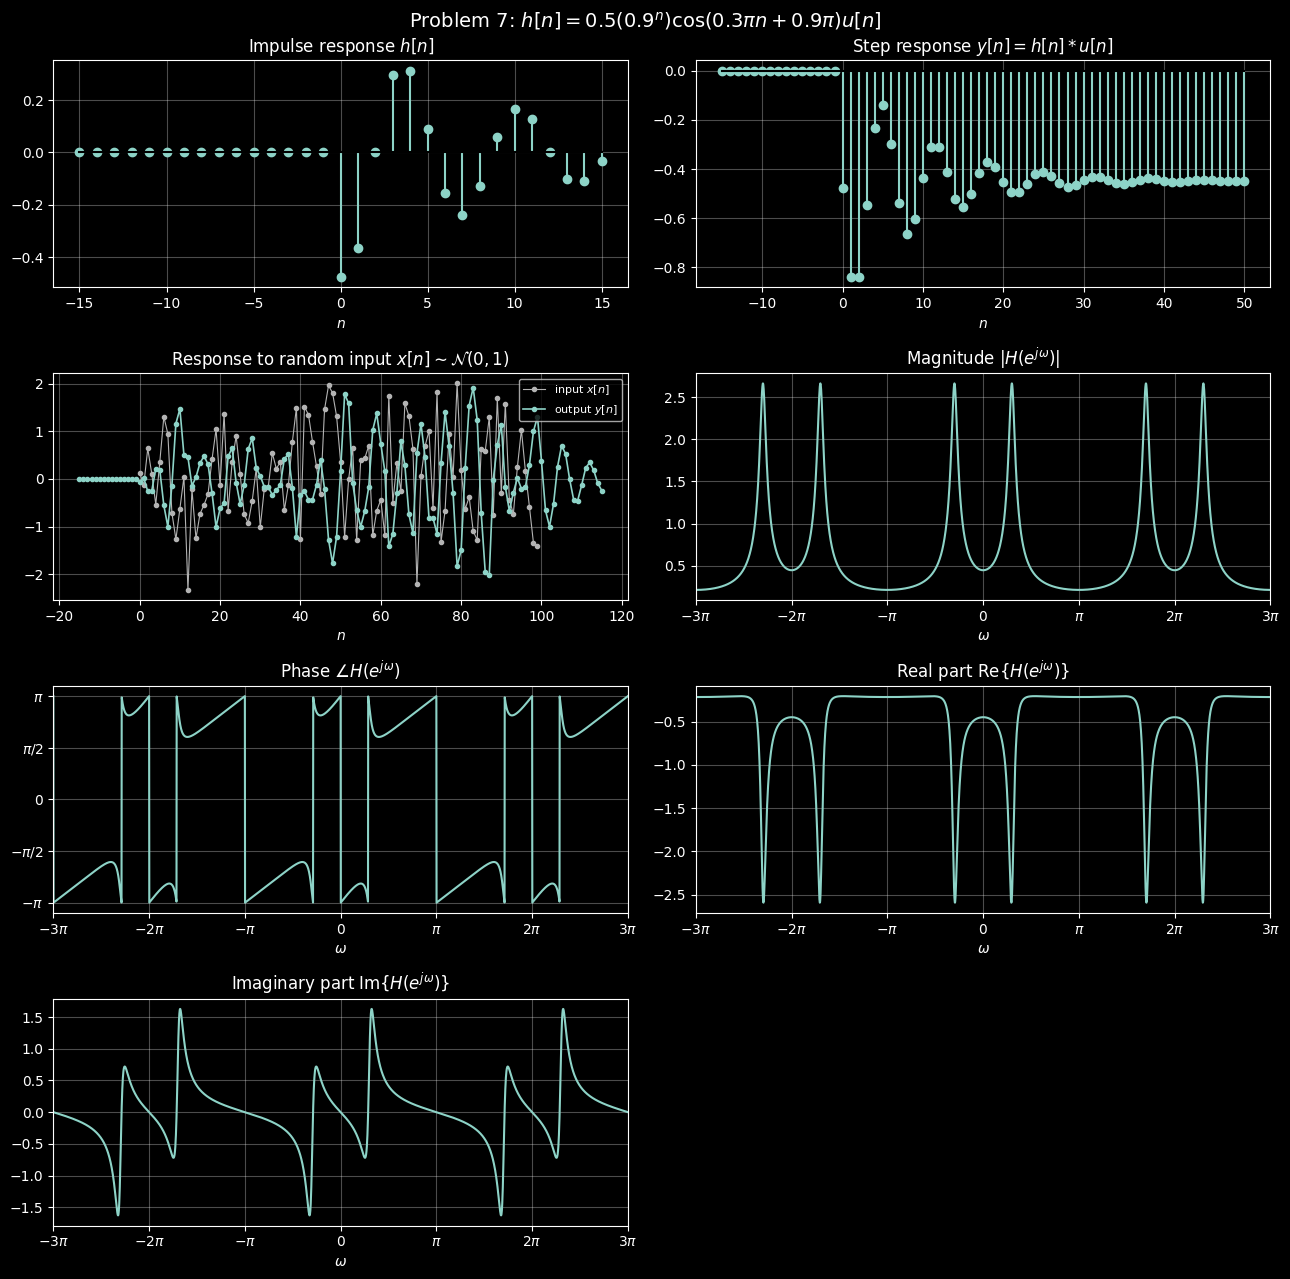

In [13]:
r, w0, phi = 0.9, 0.3 * np.pi, 0.9 * np.pi
h7 = lambda n: 0.5 * r**n * np.cos(w0 * n + phi) * u(n)

# Z{r^n cos(w0 n + phi) u[n]} = (cos(phi) - r cos(w0 - phi) z^-1) / (1 - 2r cos(w0) z^-1 + r^2 z^-2)
ba7 = (0.5 * np.array([np.cos(phi), -r * np.cos(w0 - phi)]),
       [1, -2 * r * np.cos(w0), r**2])

print("ba check:", verify_ba(h7, ba7))
analyze(h7, r"Problem 7: $h[n] = 0.5(0.9^n)\cos(0.3\pi n + 0.9\pi)u[n]$", ba7)
plt.show()

#### Classification

| Property        | Answer   | Justification                                                                                                                                                      |
|:----------------|:---------|:-------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| **Filter type** | Bandpass | When I compare $\lvert H(e^{j\omega})\rvert$ at ω = 0 (DC) and ω = π, ω = π and ω = 0 are both small with the peak at an angle somewhere in between                |
| **Causality**   | Causal   | $h[n] = 0$ for all n < 0                                                                                                                                           |
| **Stability**   | Stable   | $\lvert h[n]\rvert \le 0.5\,(0.9)^n$, so $\Sigma \lvert h[n]\rvert \le \frac{0.5}{1-0.9} = 5 < \infty$. The poles $0.9e^{\pm j0.3\pi}$ are inside the unit circle. |
| **FIR or IIR**  | IIR      | There are an infinite number of nonzero samples                                                                                                                    |

<!--
Filter type: compare |H(e^{jω})| at ω = 0 (DC) and ω = π, and look for peaks or notches in between.
  Lowpass: largest near 0, small near π.   Highpass: small near 0, largest near π.
  Bandpass: small at both 0 and π, peak in between.   Bandstop: large at 0 and π, notch in between.
Causality: causal if and only if h[n] = 0 for all n < 0 (check the impulse-response plot left of n = 0).
Stability (BIBO): stable if and only if Σ|h[n]| < ∞. For a rational H(z), equivalently all poles have |p| < 1.
  Also visible in the step response: it should settle to a finite value H(e^{j0}).
FIR vs IIR: FIR if h[n] has a finite number of nonzero samples, IIR otherwise.
-->

### Problem 8: $h[n] = 1$

#### Derivation

**Step 1: Write out $h[n]$ sample by sample.**

| $n$ | $\cdots$ | $-2$ | $-1$ | $0$ | $1$ | $2$ | $\cdots$ |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| $h[n]$ | 1 | 1 | 1 | 1 | 1 | 1 | 1 |

It's 1 for every $n$, forever in both directions. *(Impulse-response plot.)*

---

**Step 2: Output for any input $x[n]$.**

In the convolution sum every term has weight 1:

$$y[n] = \sum_{k=-\infty}^{\infty} (1)\,x[n-k]$$

Substitute $m = n - k$. As $k$ runs over all integers, so does $m$:

$$\boxed{y[n] = \sum_{m=-\infty}^{\infty} x[m]}$$

The right side doesn't depend on $n$, so every output sample equals the sum of the entire input. *(Random-input plot: a flat line at $\sum_{m=0}^{99} x[m] \approx 8.11$ for this seed. A sum of 100 unit-variance samples has standard deviation 10, so 8 is typical.)*

---

**Step 3: Step response, $x[n] = u[n]$.**

$$s[n] = \sum_{k=-\infty}^{n} h[k] = \sum_{k=-\infty}^{n} 1 = \infty$$

The step response is infinite for every $n$: a bounded input produces an unbounded output.

**What the plot shows instead.** The code builds the step input only on $n \le 99$, which is 100 ones. With a finite input, Step 2 gives $y[n] = \sum_{m=0}^{99} 1 = 100$, which is why the plot shows a flat line at 100. A longer input window would give a larger number.

---

**Step 4: Frequency response.**

$$H(e^{j\omega}) = \sum_{n=-\infty}^{\infty} e^{-j\omega n}$$

Every term has magnitude 1, so the terms never shrink and the sum does not converge as an ordinary sum. To get something we can plot, truncate to $|n| \le N$. This is exactly Problem 2's sum with $3$ replaced by $N$, so the same steps (pair $\pm n$, or re-index and use the geometric series) give

$$H_N(e^{j\omega}) = \sum_{n=-N}^{N} e^{-j\omega n} = 1 + 2\sum_{n=1}^{N}\cos(\omega n) = \boxed{\frac{\sin\big((2N+1)\omega/2\big)}{\sin(\omega/2)}}$$

The plots use $N = 200$, which is 401 terms.

---

**Step 5: What happens as $N \to \infty$.**

$H_N$ is a Dirichlet kernel, the same shape as Problem 2's but with 401 terms instead of 7:

- **Height at $\omega = 0$:** $H_N(e^{j0}) = 2N + 1 = 401$, growing without bound.
- **Width:** the first zeros are at $\omega = \pm\dfrac{2\pi}{2N+1} \approx \pm 0.016$, shrinking to 0.
- **Area over one period:** $\displaystyle\int_{-\pi}^{\pi} H_N(e^{j\omega})\,d\omega = \sum_{n=-N}^{N}\int_{-\pi}^{\pi} e^{-j\omega n}\,d\omega = 2\pi$, because only the $n = 0$ term survives the integral. The area stays $2\pi$ for every $N$.
A spike that grows taller and narrower while keeping area $2\pi$ approaches $2\pi\,\delta(\omega)$. Repeating it every $2\pi$:

$$\boxed{H(e^{j\omega}) = 2\pi\sum_{k=-\infty}^{\infty}\delta(\omega - 2\pi k)}$$

---

**Step 6: Magnitude, phase, real, and imaginary parts (truncated version).**

$H_N$ is real because $h[n]$ is even, so

$$\operatorname{Re}\{H_N\} = \frac{\sin(401\,\omega/2)}{\sin(\omega/2)}, \qquad \operatorname{Im}\{H_N\} = 0, \qquad |H_N| = \left|\frac{\sin(401\,\omega/2)}{\sin(\omega/2)}\right|$$

The phase is $0$ where $H_N > 0$ and $\pi$ where $H_N < 0$. $H_N$ changes sign at every zero, $\omega = 2\pi k/401$, which is about every 0.016 rad. That's faster than the plot's frequency grid, so the phase line fills in as a solid band between $0$ and $\pi$. For the true system, $H = 0$ away from the impulses, so its phase is undefined there.

---

**Step 7: Key values to check against the plots.**

| Quantity | Value | Where to see it |
|:---|:---|:---|
| Spike height | $2N + 1 = 401$ at $\omega = 0, \pm 2\pi$ | Magnitude and real-part plots |
| Spike area | $2\pi$ (for every $N$) | Why the spikes approach $2\pi\,\delta(\omega)$ |
| Zero spacing | $2\pi/401 \approx 0.016$ rad | Solid band in the phase plot |
| $\operatorname{Im}\{H\}$ | Exactly 0 | Flat imaginary-part plot |
| Step response | $\infty$ (plotted as 100 because of the 100-sample input window) | Step-response plot |
| Random-input output | $\sum x[m] \approx 8.11$, constant in $n$ | Flat line in the random-input plot |


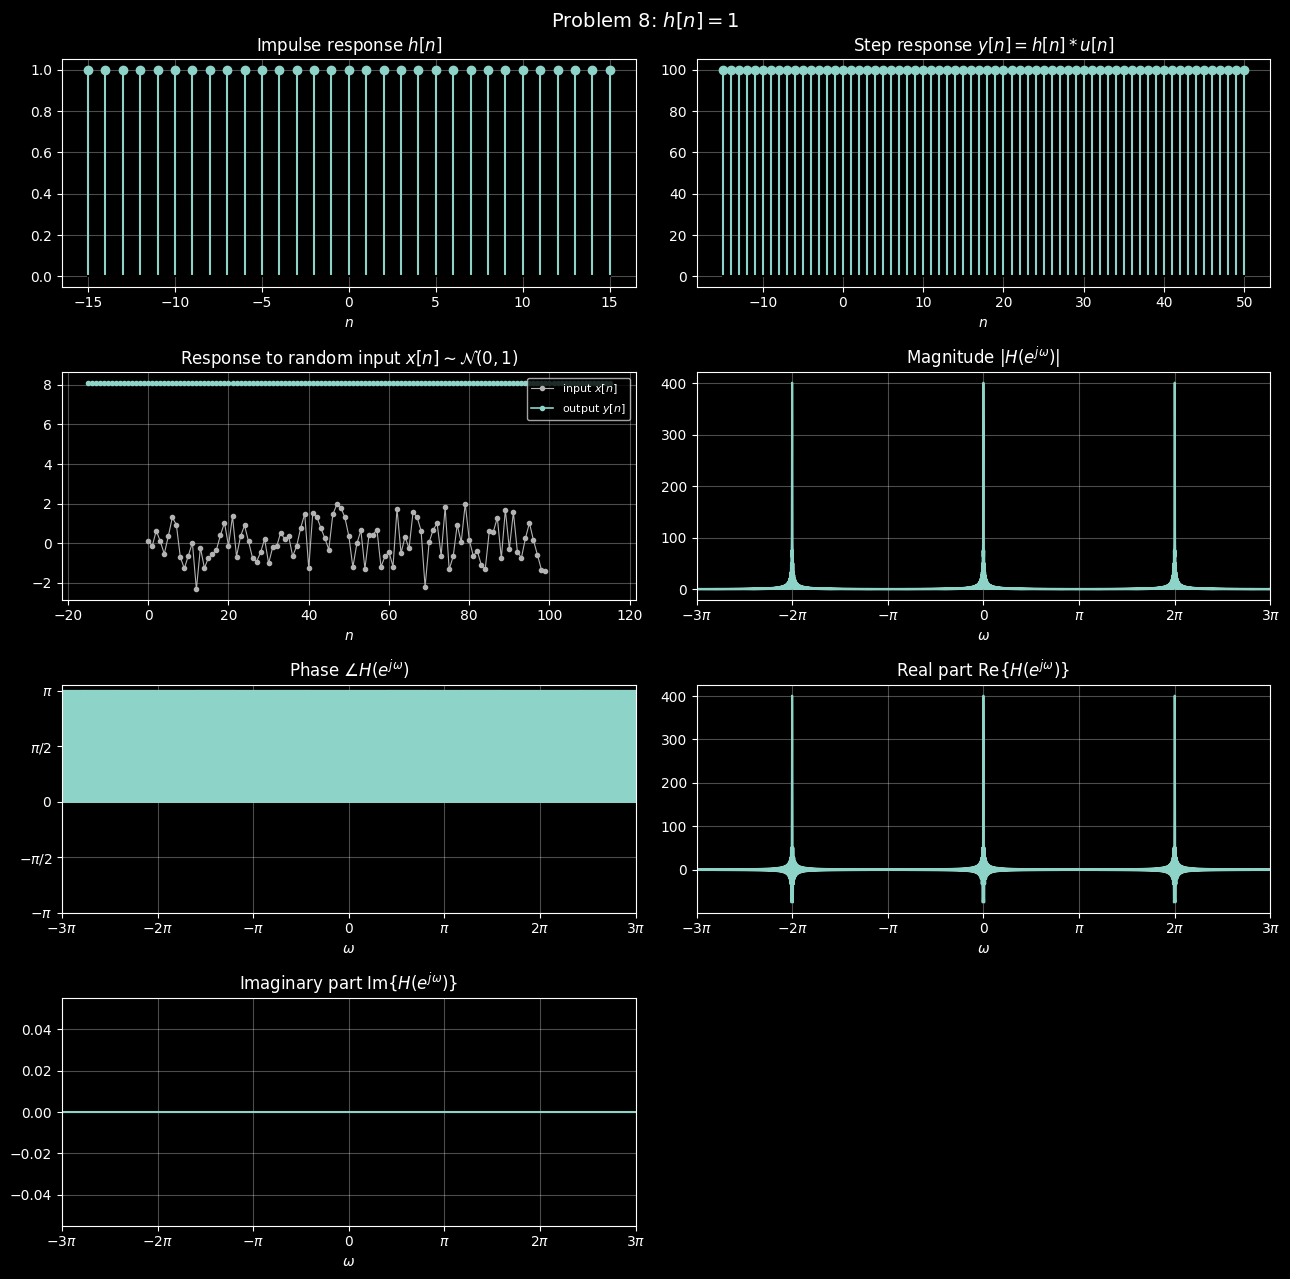

In [14]:
h8 = lambda n: np.ones(np.shape(n))
# No difference-equation form: h[n] is truncated to |n| <= N_TRUNC and summed directly

analyze(h8, r"Problem 8: $h[n] = 1$")
plt.show()

#### Classification

| Property        | Answer     | Justification                                                                            |
|:----------------|:-----------|:-----------------------------------------------------------------------------------------|
| **Filter type** | Lowpass    | $ H(e^{j\omega})$ spikes at ω = 0 with $\lvert H(e^{j\omega})\rvert = 0$ when $ω \neq 0$ |
| **Causality**   | Non-causal | There are nonzero samples when n < 0                                                     |
| **Stability**   | Unstable   | $\Sigma{\lvert h[n] \rvert} =  \infty$                                                   |
| **FIR or IIR**  | IIR        | There are an infinite number of nonzero samples                                          |

<!--
Filter type: compare |H(e^{jω})| at ω = 0 (DC) and ω = π, and look for peaks or notches in between.
  Lowpass: largest near 0, small near π.   Highpass: small near 0, largest near π.
  Bandpass: small at both 0 and π, peak in between.   Bandstop: large at 0 and π, notch in between.
Causality: causal if and only if h[n] = 0 for all n < 0 (check the impulse-response plot left of n = 0).
Stability (BIBO): stable if and only if Σ|h[n]| < ∞. For a rational H(z), equivalently all poles have |p| < 1.
  Also visible in the step response: it should settle to a finite value H(e^{j0}).
FIR vs IIR: FIR if h[n] has a finite number of nonzero samples, IIR otherwise.
-->

### Problem 9: $h[n] = 0.5\cos(0.3\pi n + 0.9\pi)$

#### Derivation

Constants: $\omega_0 = 0.3\pi$ and $\phi = 0.9\pi$, so $h[n] = 0.5\cos(\omega_0 n + \phi)$ for every $n$.

**Step 1: Write out $h[n]$ sample by sample.**

| $n$ | $\cdots$ | $-3$ | $-2$ | $-1$ | $0$ | $1$ | $2$ | $3$ | $4$ | $\cdots$ |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| $h[n]$ | $\cdots$ | 0.5 | 0.294 | $-0.155$ | $-0.476$ | $-0.405$ | 0 | 0.405 | 0.476 | $\cdots$ |

A cosine of amplitude 0.5 and period $6.\overline{6}$ samples that never decays and extends in both directions. It's not symmetric about $n = 0$ (for example $h[1] \ne h[-1]$) because of the $\phi = 0.9\pi$ offset. *(Impulse-response plot.)*

---

**Step 2: Rewrite the cosine with Euler's formula.**

Use $\cos\theta = \dfrac{e^{j\theta} + e^{-j\theta}}{2}$:

$$h[n] = \frac14\left[e^{j\phi}e^{j\omega_0 n} + e^{-j\phi}e^{-j\omega_0 n}\right]$$

Equivalently, $h[n] = 0.5\,\operatorname{Re}\left\{e^{j(\omega_0 n + \phi)}\right\}$.

---

**Step 3: Output for any input $x[n]$.**

Write the convolution with $h$ shifted, $y[n] = \sum_k x[k]\,h[n-k]$, and use $\cos(\omega_0(n-k) + \phi) = \operatorname{Re}\left\{e^{j(\omega_0 n + \phi)}\,e^{-j\omega_0 k}\right\}$:

$$y[n] = \sum_k x[k]\cdot 0.5\cos\big(\omega_0(n-k) + \phi\big) = 0.5\,\operatorname{Re}\left\{e^{j(\omega_0 n + \phi)}\underbrace{\sum_k x[k]\,e^{-j\omega_0 k}}_{X(e^{j\omega_0})}\right\}$$

The sum is the input's DTFT evaluated at the single frequency $\omega_0$. Writing $X(e^{j\omega_0}) = |X|\,e^{j\angle X}$:

$$\boxed{y[n] = 0.5\,|X(e^{j\omega_0})|\cos\big(\omega_0 n + \phi + \angle X(e^{j\omega_0})\big)}$$

Whatever the input, the output is a pure sinusoid at $\omega_0 = 0.3\pi$ for every $n$. Only the input's content at $\omega_0$ sets its amplitude and phase. *(Random-input plot: $|X(e^{j0.3\pi})| = 9.10$ for this seed, so the output is a steady sinusoid of amplitude $4.55$ running across the whole plot, including before the input starts and after it ends.)*

---

**Step 4: Step response, $x[n] = u[n]$.**

$$s[n] = \sum_{k=-\infty}^{n} 0.5\cos(0.3\pi k + 0.9\pi)$$

The terms never shrink, so the partial sums keep oscillating and never settle: the step response does not converge.

**What the plot shows instead.** The code's step input is $L = 100$ ones ($n = 0, \dots, 99$). Plug that into Step 3. The input's DTFT at $\omega_0$ is a finite geometric series, and the same steps as Problem 2, Step 5 give

$$X(e^{j\omega_0}) = \sum_{m=0}^{L-1} e^{-j\omega_0 m} = e^{-j\omega_0(L-1)/2}\,\frac{\sin(L\omega_0/2)}{\sin(\omega_0/2)}$$

$$y[n] = 0.5\,\frac{\sin(L\omega_0/2)}{\sin(\omega_0/2)}\cos\!\left(\omega_0 n + \phi - \frac{\omega_0(L-1)}{2}\right)$$

With $L = 100$: $\sin(100 \cdot 0.15\pi) = \sin(15\pi) = 0$, so $y[n] = 0$ exactly. The input window covers exactly 15 periods of the cosine, and a cosine sums to zero over whole periods. The $10^{-14}$ values in the plot are round-off. With $L = 101$ the amplitude would be 0.50, and the largest possible is $0.5/\sin(0.15\pi) \approx 1.10$.

---

**Step 5: Frequency response.**

Truncate to $|n| \le N$ and apply Problem 8's result to each exponential from Step 2. Each one is Problem 8's sum shifted in frequency by $\pm\omega_0$:

$$H_N(e^{j\omega}) = \frac14 e^{j\phi}\sum_{n=-N}^{N} e^{-j(\omega - \omega_0)n} + \frac14 e^{-j\phi}\sum_{n=-N}^{N} e^{-j(\omega + \omega_0)n}
= \frac14 e^{j\phi}\,D_N(\omega - \omega_0) + \frac14 e^{-j\phi}\,D_N(\omega + \omega_0)$$

where $D_N(\theta) = \dfrac{\sin\big((2N+1)\theta/2\big)}{\sin(\theta/2)}$ is Problem 8's Dirichlet kernel. As $N \to \infty$, each $D_N$ becomes $2\pi\,\delta$:

$$\boxed{H(e^{j\omega}) = \frac{\pi}{2}\sum_{k=-\infty}^{\infty}\left[e^{j0.9\pi}\,\delta(\omega - 0.3\pi - 2\pi k) + e^{-j0.9\pi}\,\delta(\omega + 0.3\pi - 2\pi k)\right]}$$

---

**Step 6: Magnitude, phase, real, and imaginary parts (truncated version, $N = 200$).**

Near $\omega = +\omega_0$ the first kernel dominates, with peak $D_N(0) = 401$:

$$H_N(e^{j0.3\pi}) \approx \frac{401}{4}\,e^{j0.9\pi} = 100.25\left[\cos(0.9\pi) + j\sin(0.9\pi)\right] \approx -95.3 + 31.0j$$

Near $\omega = -\omega_0$ the second kernel dominates and gives the complex conjugate, $\approx -95.3 - 31.0j$. Away from $\pm\omega_0$, both kernels are tiny compared with these spikes. The phase is meaningful only at the spikes, where it equals $\pm\phi = \pm 0.9\pi$. Elsewhere the true $H$ is 0 and its phase is undefined, so the plotted phase is a filled band, as in Problem 8.

---

**Step 7: Key values to check against the plots.**

| Quantity | Value | Where to see it |
|:---|:---|:---|
| Spike locations | $\omega = \pm 0.3\pi$ (and $\pm 1.7\pi$, $\pm 2.3\pi$ by periodicity) | Magnitude plot |
| Spike height | $\tfrac{401}{4} \approx 100$ | Magnitude plot |
| Value at $+0.3\pi$ | $\approx 100\,e^{j0.9\pi} = -95.3 + 31.0j$ | Real part $\approx -95$; imaginary part $\approx +31$ |
| Value at $-0.3\pi$ | $\approx -95.3 - 31.0j$ | Real part $\approx -95$; imaginary part $\approx -31$ |
| Impulse weights (true $H$) | $\tfrac{\pi}{2}e^{\pm j0.9\pi}$ | Limit as $N \to \infty$ |
| Step response | Does not converge (plotted as 0 because 100 samples is exactly 15 periods) | Step-response plot, $10^{-14}$ scale |
| Random-input output | Sinusoid at $0.3\pi$, amplitude $0.5\,\lvert X(e^{j0.3\pi})\rvert = 4.55$ | Random-input plot |

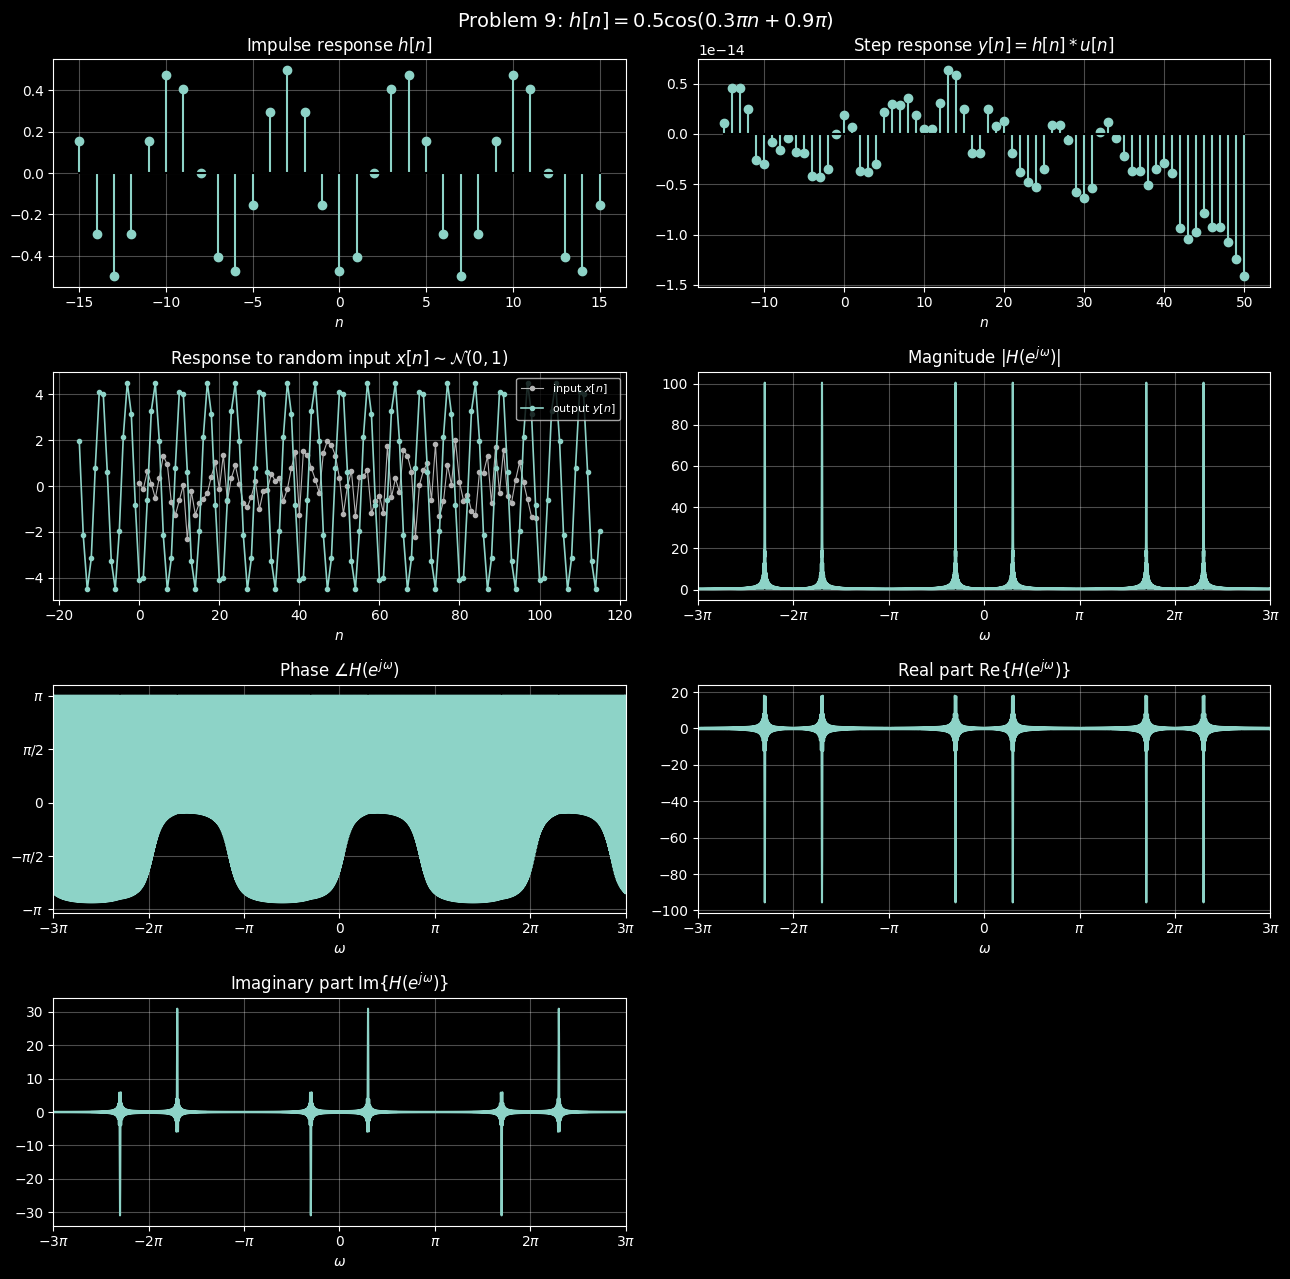

In [15]:
h9 = lambda n: 0.5 * np.cos(0.3 * np.pi * n + 0.9 * np.pi)
# Two-sided and not absolutely summable: truncated to |n| <= N_TRUNC

analyze(h9, r"Problem 9: $h[n] = 0.5\cos(0.3\pi n + 0.9\pi)$")
plt.show()

#### Classification

| Property        | Answer     | Justification                                                                        |
|:----------------|:-----------|:-------------------------------------------------------------------------------------|
| **Filter type** | Bandpass   | $\lvert H(e^{j\omega})\rvert = 0$ when ω = 0 and ω = π and is $\infty$ when ω = 0.3π |
| **Causality**   | Non-causal | There are nonzero samples when n < 0                                                 |
| **Stability**   | Unstable   | The sinusoidal in $h[n]$ makes $h[n]$ nonconvergent                                  |
| **FIR or IIR**  | IIR        | There are an infinite number of nonzero samples                                      |

<!--
Filter type: compare |H(e^{jω})| at ω = 0 (DC) and ω = π, and look for peaks or notches in between.
  Lowpass: largest near 0, small near π.   Highpass: small near 0, largest near π.
  Bandpass: small at both 0 and π, peak in between.   Bandstop: large at 0 and π, notch in between.
Causality: causal if and only if h[n] = 0 for all n < 0 (check the impulse-response plot left of n = 0).
Stability (BIBO): stable if and only if Σ|h[n]| < ∞. For a rational H(z), equivalently all poles have |p| < 1.
  Also visible in the step response: it should settle to a finite value H(e^{j0}).
FIR vs IIR: FIR if h[n] has a finite number of nonzero samples, IIR otherwise.
-->

## What, if anything, did you learn from this homework?

Problems 1 & 2: A time shift changes the phase.

Problem 5 & 6: Multiplying an impulse response with $(-1)^n$ shifts the spectrum by $pi$, making a lowpass into a highpass.

Problem 7: $\lvert H(e^{j\omega})\rvert$ is influenced by the location of the poles. The closer a pole is to the unit circle, the more $\lvert H(e^{j\omega})\rvert$ will peak.


## What new questions, if any, do you have?

I have no questions at this time.